# N6 — Analyse descriptive du sous-échantillon « Afrique »

Ce notebook est le livrable analytique du pipeline. Il filtre la base fusionnée sur une liste de pays, puis enchaîne quatre parties, du général au particulier :

1. **profil** : distributions univariées des variables socio-démographiques ;
2. **variables d'opinion et cibles** : variables issues de la base d'enquête ;
3. **variables du questionnaire** : variables imputées par Monte Carlo, signalées comme telles ;
4. **croisements** : tableaux de contingence entre la variable cible `intention_to_migrate_legal` et chaque variable explicative.

> ⚠️ **Données synthétiques** — ce notebook s'exécute sur des données générées par `generate_dummy_data.py`. Les valeurs, proportions et graphiques affichés sont aléatoires et ne décrivent aucune population réelle.

| | Fichiers |
|---|---|
| **Entrée** | `data/2_Donnees_nettoyees/base_fusionnee_nettoyee.xlsx` (produit par N5) |
| **Sortie** | graphiques uniquement |

## ⚠️ Traçabilité des variables imputées

Une partie des variables provient du questionnaire et a été imputée par Monte Carlo dans N4 pour toutes les lignes issues de la base d'enquête. Ces variables conservent leur distribution marginale mais **aucune corrélation avec les autres variables** (voir N4) : elles peuvent être décrites, pas croisées.

- **Imputées par Monte Carlo** (issues du questionnaire) : `Revenu`, `Source_revenu_*`, `Taille_menage`, `Decideur_financier`, `Choc_economique`, `Acces_credit`, `Proches_europe`, `Proche_*`, `Nationalite_francaise`, `Retour_pays`, `Mariage_blanc`, `Raisons_migration`, `Intention_envoyer_argent`, `Montant_envois`, `Frequence_envois`, `Pays_etape`, `Frequence_virements`.
- **Non imputées par Monte Carlo** (issues de la base d'enquête) : `Country`, `Age`, `Genderf`, `Social statusf`, `Educationf`, `Professional situationf`, `Regionf`, `Bankaccount`, `Remit`, variables de confiance, `Corruption (0  1)`, `intention_to_migrate_legal`, `intention_to_migrate_illegal`.

Chaque graphique et chaque croisement mobilisant une variable imputée est signalé par ⚠️ dans son titre.

## Chargement de la base et filtrage géographique

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df2 = pd.read_excel("../data/2_Donnees_nettoyees/base_fusionnee_nettoyee.xlsx")

print(f"Base fusionnée totale : {df2.shape[0]} lignes × {df2.shape[1]} colonnes")
print(f"\nPays présents dans la base :")
print(sorted(df2["Country"].dropna().unique()))

Base fusionnée totale : 5062 lignes × 44 colonnes

Pays présents dans la base :
['ALBANIA', 'ALGERIA', 'BENIN', 'BURKINA FASO', 'ECUADOR', 'EGYPT', 'IRAQ', 'ITALY', 'IVORY COAST', 'JORDAN', 'KOSOVO', 'LEBANON', 'LIBYA', 'MADAGASCAR', 'MAURITANIA', 'MAURITIUS', 'MOROCCO', 'PALESTINE', 'SENEGAL', 'SPAIN', 'SUDAN', 'TOGO', 'TUNISIA', 'TURKEY']


### Filtre géographique

Le sous-échantillon est obtenu par un masque `isin()` sur une liste explicite de libellés de `Country`, puis copié (`.copy()`) pour que les transformations ultérieures ne modifient pas la base complète. Le bloc affiche l'effectif avant et après filtrage, et le nombre de répondants conservés par pays.

In [2]:
pays_africains = [
    "ALGERIA", "EGYPT", "LIBYA", "MAURITANIA", "MOROCCO", "SUDAN", "TUNISIA",
    "BENIN", "BURKINA FASO", "CENTRAL AFRICAN REPUBLIC", "IVORY COAST",
    "MADAGASCAR", "MAURITIUS", "SENEGAL", "TOGO"
]

df_africa = df2[df2["Country"].isin(pays_africains)].copy()

print(f"Avant filtrage : {df2.shape[0]} répondants")
print(f"Après filtrage (Afrique uniquement) : {df_africa.shape[0]} répondants")
print(f"Soit {df_africa.shape[0] / df2.shape[0] * 100:.1f}% de la base initiale")
print(f"\nPays conservés et nombre de répondants :")
print(df_africa["Country"].value_counts().sort_values(ascending=False))

Avant filtrage : 5062 répondants
Après filtrage (Afrique uniquement) : 3423 répondants
Soit 67.6% de la base initiale

Pays conservés et nombre de répondants :
Country
LIBYA           566
EGYPT           556
SUDAN           514
ALGERIA         454
MOROCCO         454
MAURITANIA      431
TUNISIA         422
SENEGAL           6
BENIN             4
BURKINA FASO      4
MAURITIUS         4
TOGO              4
MADAGASCAR        3
IVORY COAST       1
Name: count, dtype: int64


In [3]:
# Configuration globale pour tous les graphiques
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print(f"Nombre total de répondants africains : {len(df_africa):,}".replace(",", " "))
print(f"Nombre de pays africains représentés : {df_africa['Country'].nunique()}")

Nombre total de répondants africains : 3 423
Nombre de pays africains représentés : 14


## Partie 1 — Profil des répondants

Distributions univariées des variables socio-démographiques : pays, âge, genre, statut social, zone de résidence, éducation, situation professionnelle. Les graphiques reprennent les conventions de N0 (fréquences relatives en %, libellés traduits par dictionnaire).

### Répartition par pays

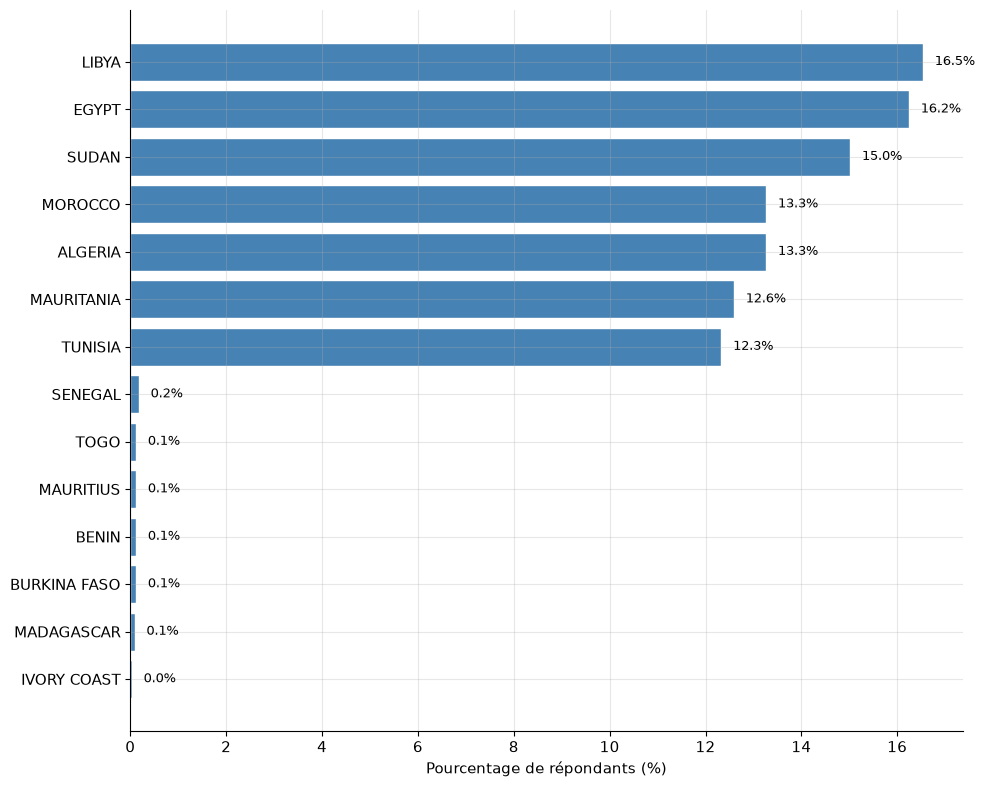

In [4]:
repartition_pays = df_africa["Country"].value_counts(normalize=True).sort_values() * 100
plt.figure(figsize=(10, 8))
bars = plt.barh(repartition_pays.index, repartition_pays.values, color="steelblue", edgecolor="white")
for i, (pays, valeur) in enumerate(repartition_pays.items()):
    plt.text(valeur + max(repartition_pays) * 0.01, i, f" {valeur:.1f}%", va="center", fontsize=9)
plt.xlabel("Pourcentage de répondants (%)")
plt.tight_layout()
plt.show()

Barres horizontales des fréquences relatives triées. Le décalage des étiquettes est proportionnel à la valeur maximale (`max(...) * 0.01`) pour rester lisible quelle que soit l'échelle. Les groupes à très faible effectif apparaissent proches de 0 % : leur part se lit avec l'effectif absolu affiché par le bloc de filtrage.

### Distribution de l'âge

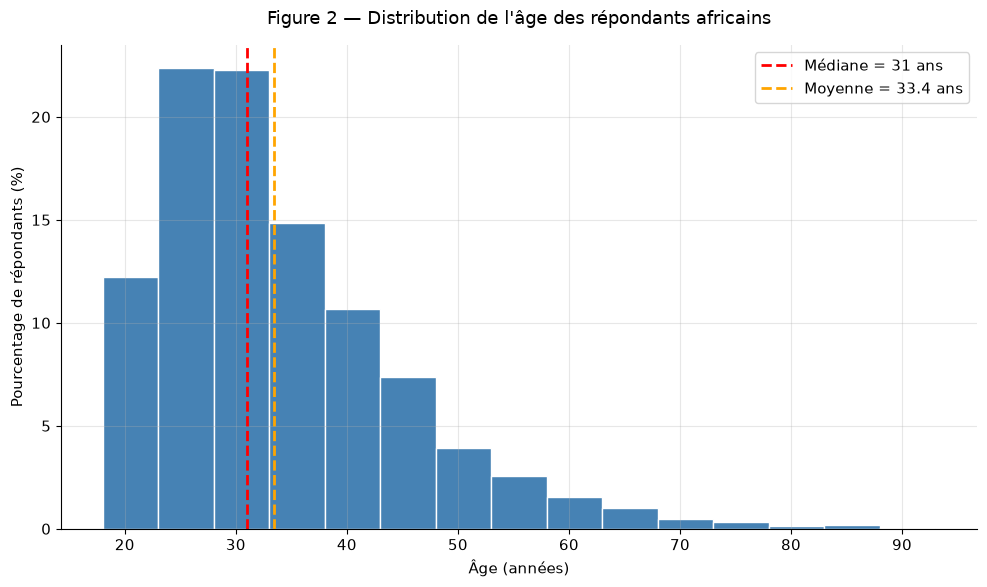


Âge minimum : 18 ans | Âge maximum : 96 ans
Âge moyen : 33.4 ans | Âge médian : 31 ans


In [5]:
plt.figure(figsize=(10, 6))
poids = np.ones_like(df_africa["Age"]) / len(df_africa) * 100
nbr_barre = range(int(df_africa["Age"].min()), int(df_africa["Age"].max()), 5)
plt.hist(df_africa["Age"], bins=nbr_barre, weights=poids, color="steelblue", edgecolor="white")
plt.axvline(df_africa["Age"].median(), color="red", linestyle="--", linewidth=2, label=f"Médiane = {df_africa['Age'].median():.0f} ans")
plt.axvline(df_africa["Age"].mean(), color="orange", linestyle="--", linewidth=2, label=f"Moyenne = {df_africa['Age'].mean():.1f} ans")
plt.xlabel("Âge (années)")
plt.ylabel("Pourcentage de répondants (%)")
plt.title("Figure 2 — Distribution de l'âge des répondants africains", fontsize=13, pad=15)
plt.legend()
plt.tight_layout()
plt.show()
print(f"\nÂge minimum : {df_africa['Age'].min()} ans | Âge maximum : {df_africa['Age'].max()} ans")
print(f"Âge moyen : {df_africa['Age'].mean():.1f} ans | Âge médian : {df_africa['Age'].median():.0f} ans")

Histogramme pondéré en pourcentages (classes de 5 ans), médiane et moyenne en surimpression, puis affichage des statistiques résumées (minimum, maximum, moyenne, médiane) pour compléter la lecture graphique.

### Répartition par genre

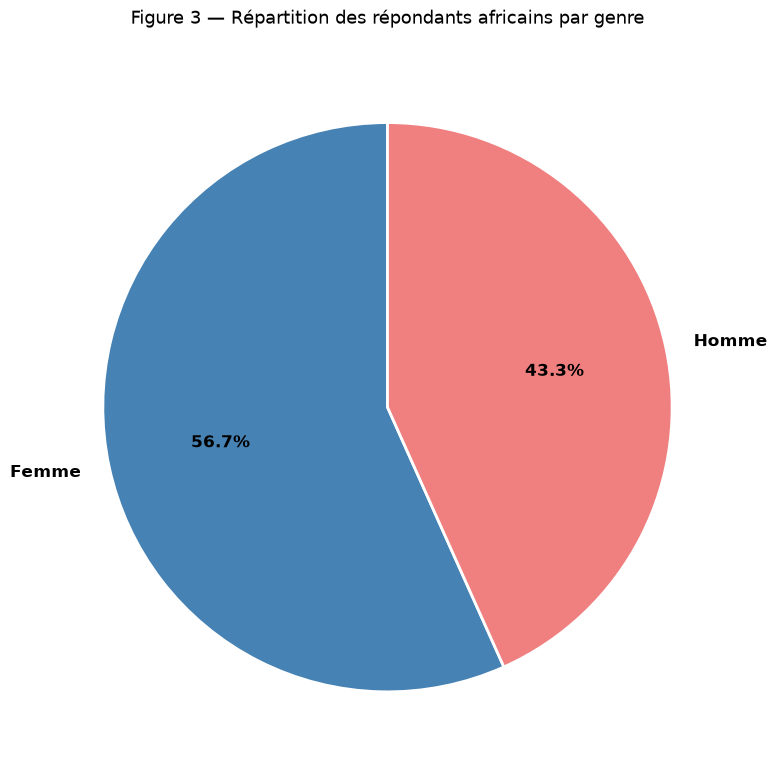

In [6]:
correspondance = {0: "Femme", 1: "Homme"}
genre = df_africa["Genderf"].value_counts(normalize=True).sort_index() * 100
genre.index = genre.index.map(correspondance)
plt.figure(figsize=(8, 8))
plt.pie(genre.values, labels=genre.index, autopct="%1.1f%%", colors=["steelblue", "lightcoral"], startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 12, "fontweight": "bold"})
plt.title("Figure 3 — Répartition des répondants africains par genre", fontsize=13, pad=20)
plt.tight_layout()
plt.show()

Version vectorisée du calcul de N0 : `value_counts(normalize=True)`, traduction des codes par dictionnaire, puis diagramme en secteurs.

### Répartition par statut social

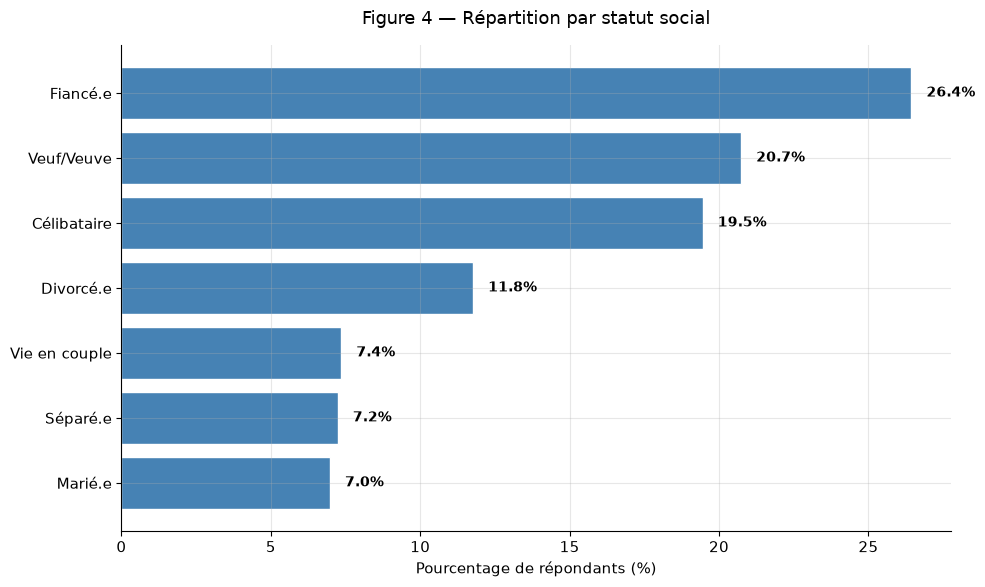

In [7]:
correspondance = {1: "Célibataire", 2: "Vie en couple", 3: "Fiancé.e", 4: "Marié.e", 5: "Divorcé.e", 6: "Séparé.e", 7: "Veuf/Veuve"}
statut_social = df_africa["Social statusf"].value_counts(normalize=True).sort_values() * 100
statut_social.index = statut_social.index.map(correspondance)
plt.figure(figsize=(10, 6))
bars = plt.barh(statut_social.index, statut_social.values, color="steelblue", edgecolor="white")
for bar, valeur in zip(bars, statut_social.values):
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f"{valeur:.1f}%", va="center", fontsize=10, fontweight="bold")
plt.xlabel("Pourcentage de répondants (%)")
plt.title("Figure 4 — Répartition par statut social", fontsize=13, pad=15)
plt.tight_layout()
plt.show()

Barres horizontales triées, avec des étiquettes de valeur positionnées à droite de chaque barre (`bar.get_width()`).

### Répartition par zone de résidence

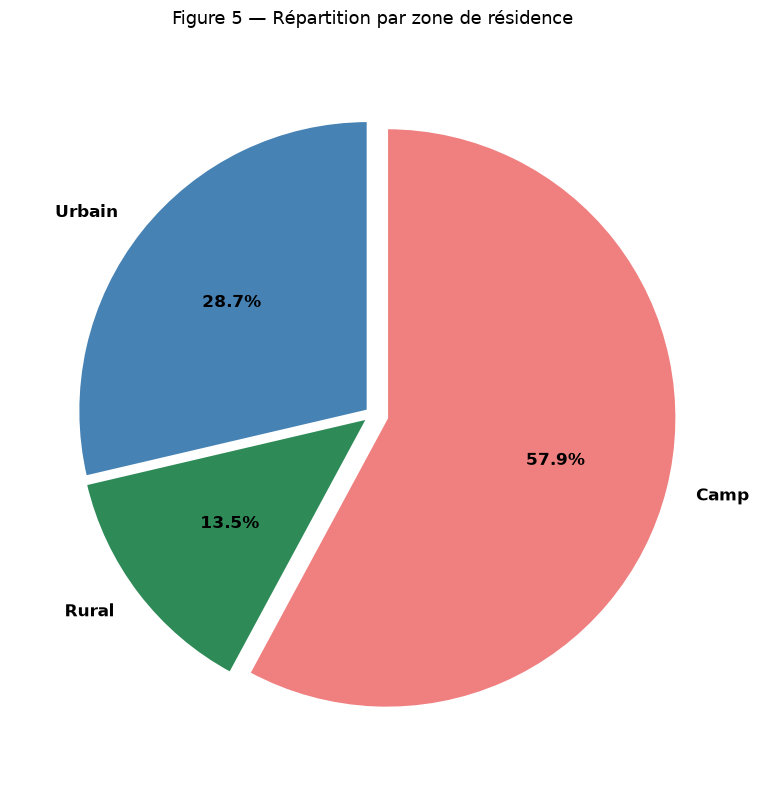

In [8]:
correspondance = {1: "Urbain", 2: "Rural", 3: "Camp"}
region = df_africa["Regionf"].value_counts(normalize=True).sort_index() * 100
region.index = region.index.map(correspondance)
plt.figure(figsize=(8, 8))
explode_list = [0.02] * (len(region) - 1) + [0.05] if len(region) > 1 else [0.02] * len(region)
plt.pie(region.values, labels=region.index, autopct="%1.1f%%", colors=["steelblue", "seagreen", "lightcoral"][:len(region)], startangle=90, explode=explode_list, wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 12, "fontweight": "bold"})
plt.title("Figure 5 — Répartition par zone de résidence", fontsize=13, pad=20)
plt.tight_layout()
plt.show()

La liste `explode_list` et la palette sont construites dynamiquement à partir du nombre de modalités présentes (`len(region)`) : le graphique reste valide même si le filtrage fait disparaître une modalité.

### Répartition par niveau d'éducation

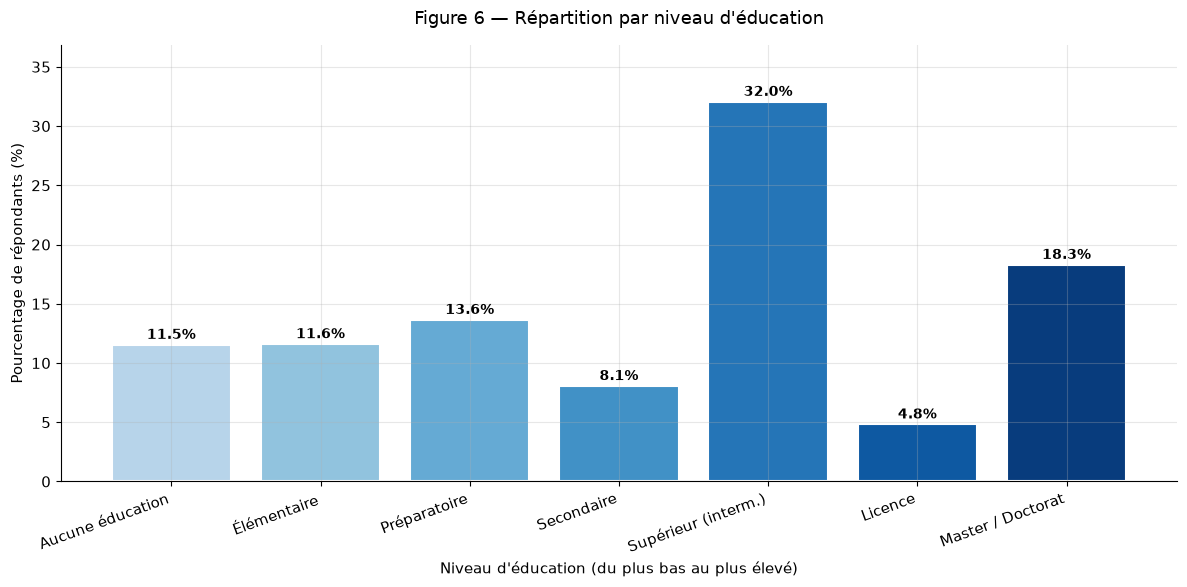

In [9]:
correspondance = {1: "Aucune éducation", 2: "Élémentaire", 3: "Préparatoire", 4: "Secondaire", 5: "Supérieur (interm.)", 6: "Licence", 7: "Master / Doctorat"}
education = df_africa["Educationf"].value_counts(normalize=True).sort_index() * 100
education.index = education.index.map(correspondance)
import matplotlib.cm as cm
couleurs = cm.Blues(np.linspace(0.3, 0.95, len(education)))
plt.figure(figsize=(12, 6))
bars = plt.bar(education.index, education.values, color=couleurs, edgecolor="white", linewidth=1.5)
for bar, valeur in zip(bars, education.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f"{valeur:.1f}%", ha="center", fontsize=10, fontweight="bold")
plt.xlabel("Niveau d'éducation (du plus bas au plus élevé)")
plt.ylabel("Pourcentage de répondants (%)")
plt.title("Figure 6 — Répartition par niveau d'éducation", fontsize=13, pad=15)
plt.xticks(rotation=20, ha="right")
plt.ylim(0, max(education.values) * 1.15)
plt.tight_layout()
plt.show()

Variable ordinale : ordre des codes conservé et dégradé de couleurs séquentiel (`cm.Blues`).

### Répartition par situation professionnelle

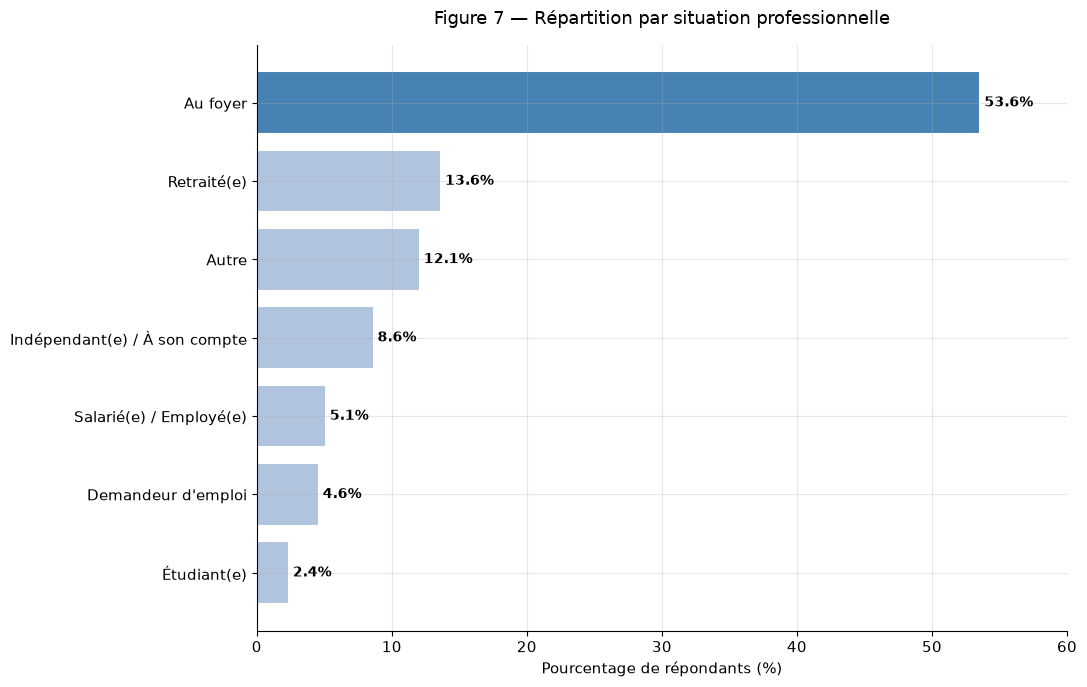

In [10]:
correspondance = {1: "Salarié(e) / Employé(e)", 2: "Indépendant(e) / À son compte", 3: "Retraité(e)", 4: "Au foyer", 5: "Étudiant(e)", 6: "Demandeur d'emploi", 7: "Autre"}
situation_pro = df_africa["Professional situationf"].value_counts(normalize=True) * 100
situation_pro.index = situation_pro.index.map(correspondance)
situation_pro = situation_pro.sort_values()
couleurs = ["lightsteelblue"] * len(situation_pro)
couleurs[-1] = "steelblue"
plt.figure(figsize=(11, 7))
bars = plt.barh(situation_pro.index, situation_pro.values, color=couleurs, edgecolor="white", linewidth=1.5)
for bar, valeur in zip(bars, situation_pro.values):
    plt.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2, f"{valeur:.1f}%", va="center", fontsize=10, fontweight="bold")
plt.xlabel("Pourcentage de répondants (%)")
plt.title("Figure 7 — Répartition par situation professionnelle", fontsize=13, pad=15)
plt.xlim(0, max(situation_pro.values) * 1.12)
plt.tight_layout()
plt.show()

Barres horizontales triées, modalité la plus fréquente mise en évidence par une couleur distincte.

## Partie 2 — Variables d'opinion et variables cibles (non imputées par Monte Carlo)

Variables binaires issues de la base d'enquête : confiance institutionnelle et interpersonnelle, perception de la corruption, intentions migratoires, bancarisation et envois de fonds.

### Confiance institutionnelle

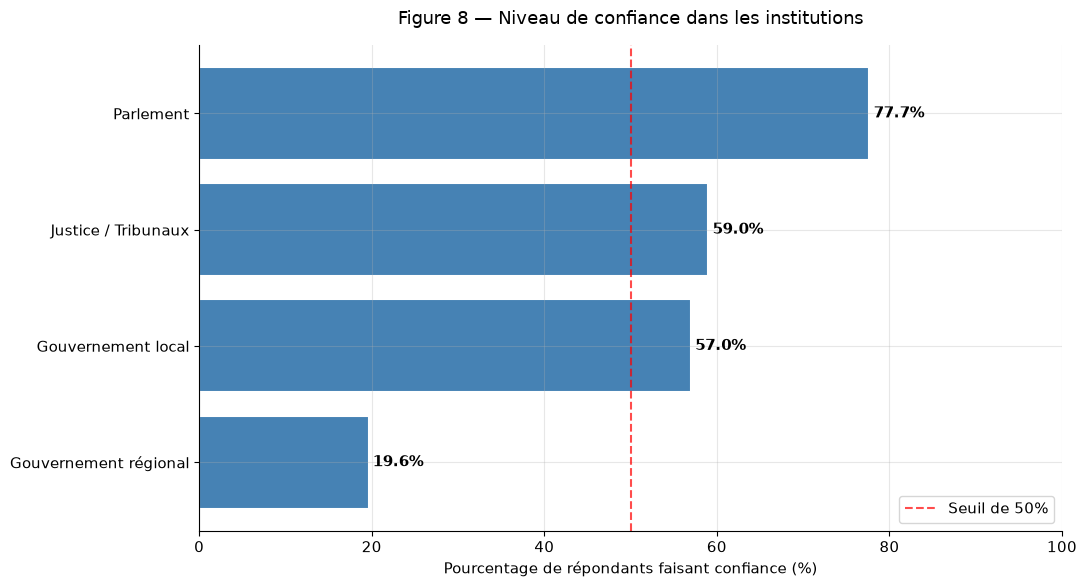

In [11]:
institutions = {
    "Justice / Tribunaux": df_africa["TrustCourts"].mean() * 100,
    "Parlement": df_africa["Trust_Parliament"].mean() * 100,
    "Gouvernement local": df_africa["TrustLocalGovernement"].mean() * 100,
    "Gouvernement régional": df_africa["Trust_Regiol_Governement"].mean() * 100
}
institutions_triees = dict(sorted(institutions.items(), key=lambda x: x[1]))
plt.figure(figsize=(11, 6))
bars = plt.barh(list(institutions_triees.keys()), list(institutions_triees.values()), color="steelblue", edgecolor="white", linewidth=1.5)
for bar, valeur in zip(bars, institutions_triees.values()):
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f"{valeur:.1f}%", va="center", fontsize=11, fontweight="bold")
plt.axvline(50, color="red", linestyle="--", linewidth=1.5, alpha=0.7, label="Seuil de 50%")
plt.xlabel("Pourcentage de répondants faisant confiance (%)")
plt.title("Figure 8 — Niveau de confiance dans les institutions", fontsize=13, pad=15)
plt.xlim(0, 100)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Proportion de `1` pour quatre variables de confiance, triée et comparée à une ligne de référence à 50 %.

### Confiance interpersonnelle généralisée

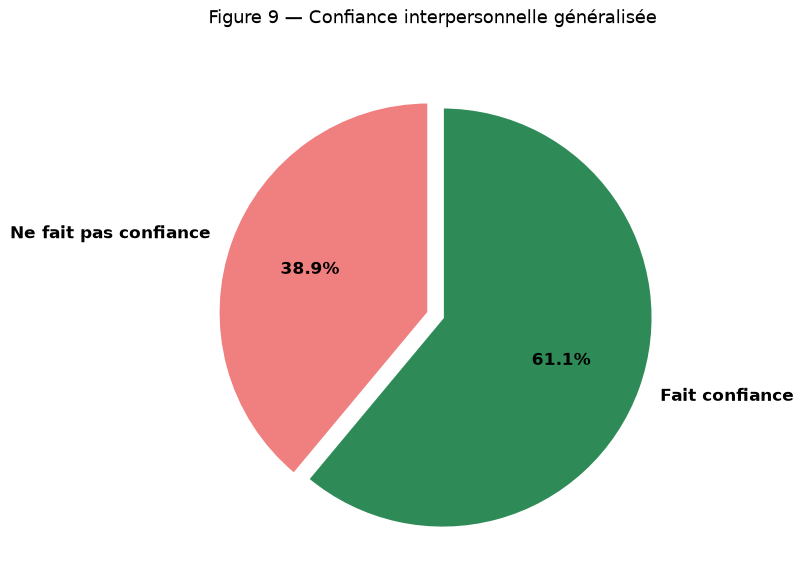

In [12]:
correspondance = {0: "Ne fait pas confiance", 1: "Fait confiance"}
confiance = df_africa["GeneralizedTrsut"].value_counts(normalize=True).sort_index() * 100
confiance.index = confiance.index.map(correspondance)
plt.figure(figsize=(8, 8))
plt.pie(confiance.values, labels=confiance.index, autopct="%1.1f%%", colors=["lightcoral", "seagreen"], startangle=90, explode=[0.02, 0.05], wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 12, "fontweight": "bold"})
plt.title("Figure 9 — Confiance interpersonnelle généralisée", fontsize=13, pad=20)
plt.tight_layout()
plt.show()

Diagramme en secteurs d'une variable binaire ; `explode` décale légèrement la modalité d'intérêt.

### Perception de la corruption

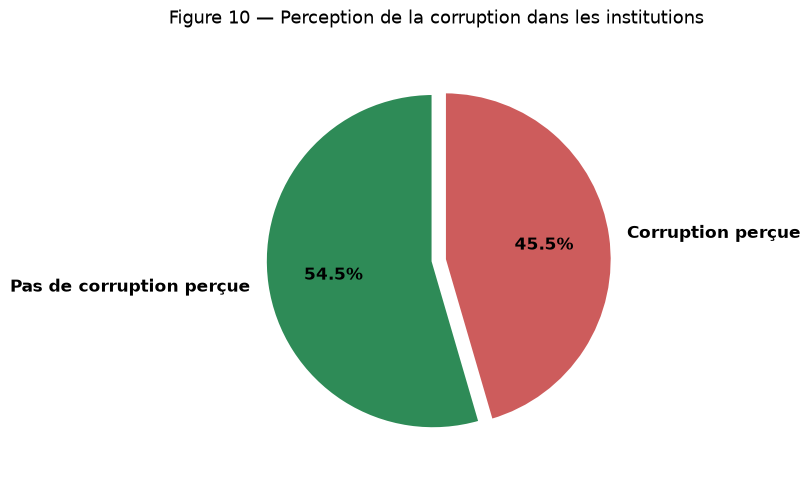

In [13]:
correspondance = {0: "Pas de corruption perçue", 1: "Corruption perçue"}
corruption = df_africa["Corruption (0  1)"].value_counts(normalize=True).sort_index() * 100
corruption.index = corruption.index.map(correspondance)
plt.figure(figsize=(8, 8))
plt.pie(corruption.values, labels=corruption.index, autopct="%1.1f%%", colors=["seagreen", "indianred"], startangle=90, explode=[0.02, 0.05], wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 12, "fontweight": "bold"})
plt.title("Figure 10 — Perception de la corruption dans les institutions", fontsize=13, pad=20)
plt.tight_layout()
plt.show()

Même construction pour `Corruption (0  1)`, version binarisée de l'échelle de corruption.

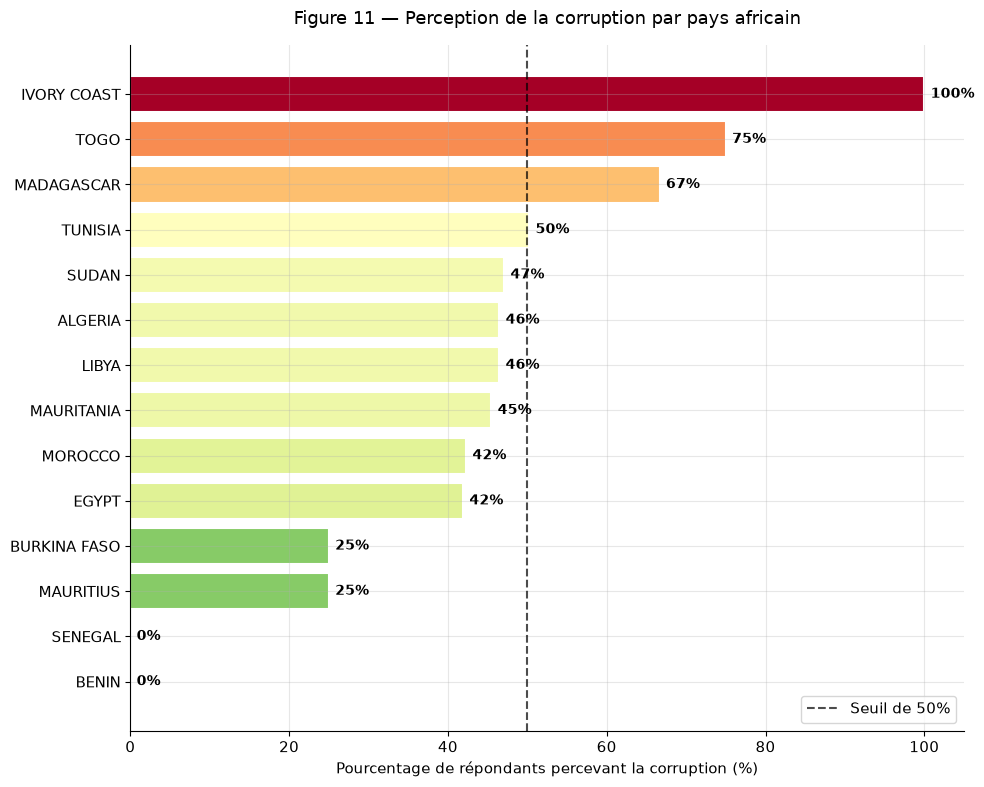

In [14]:
# Corruption perçue par pays africain
corruption_par_pays = df_africa.groupby("Country")["Corruption (0  1)"].mean() * 100
corruption_par_pays = corruption_par_pays.sort_values()
couleurs = plt.cm.RdYlGn_r(corruption_par_pays.values / 100)
plt.figure(figsize=(10, 8))
bars = plt.barh(corruption_par_pays.index, corruption_par_pays.values, color=couleurs, edgecolor="white", linewidth=1.5)
for bar, valeur in zip(bars, corruption_par_pays.values):
    plt.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height()/2, f"{valeur:.0f}%", va="center", fontsize=10, fontweight="bold")
plt.axvline(50, color="black", linestyle="--", linewidth=1.5, alpha=0.7, label="Seuil de 50%")
plt.xlabel("Pourcentage de répondants percevant la corruption (%)")
plt.title("Figure 11 — Perception de la corruption par pays africain", fontsize=13, pad=15)
plt.xlim(0, 105)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Déclinaison par pays : `groupby("Country").mean()` et couleur indexée sur la valeur (`RdYlGn_r`). L'axe X est étendu à 105 % pour que les étiquettes des barres à 100 % restent visibles. Pour les pays à faible effectif, la proportion est mécaniquement saturée (0 % ou 100 %) dès qu'un groupe ne compte qu'un ou deux répondants.

### Intention de migrer légalement

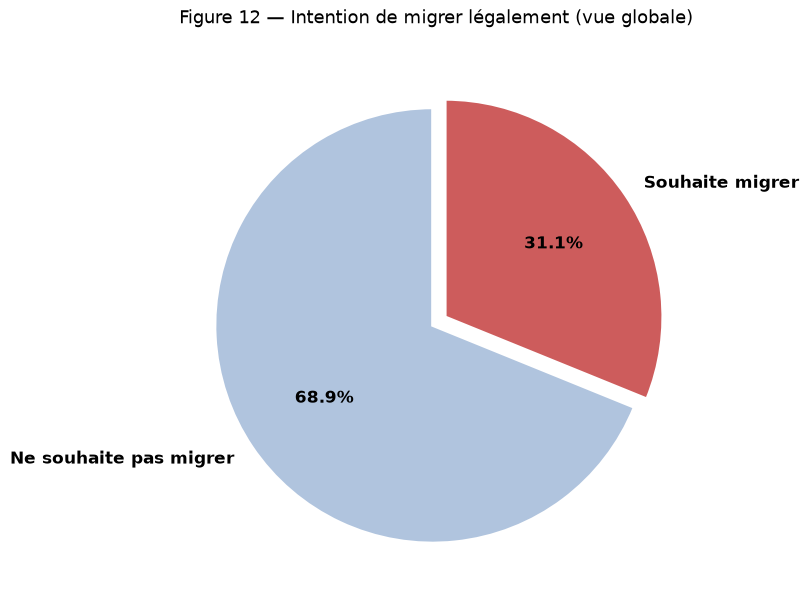

In [15]:
correspondance = {0: "Ne souhaite pas migrer", 1: "Souhaite migrer"}
intention = df_africa["intention_to_migrate_legal"].value_counts(normalize=True).sort_index() * 100
intention.index = intention.index.map(correspondance)
plt.figure(figsize=(8, 8))
plt.pie(intention.values, labels=intention.index, autopct="%1.1f%%", colors=["lightsteelblue", "indianred"], startangle=90, explode=[0.02, 0.05], wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 12, "fontweight": "bold"})
plt.title("Figure 12 — Intention de migrer légalement (vue globale)", fontsize=13, pad=20)
plt.tight_layout()
plt.show()

Vue globale de la variable cible `intention_to_migrate_legal` (diagramme en secteurs).

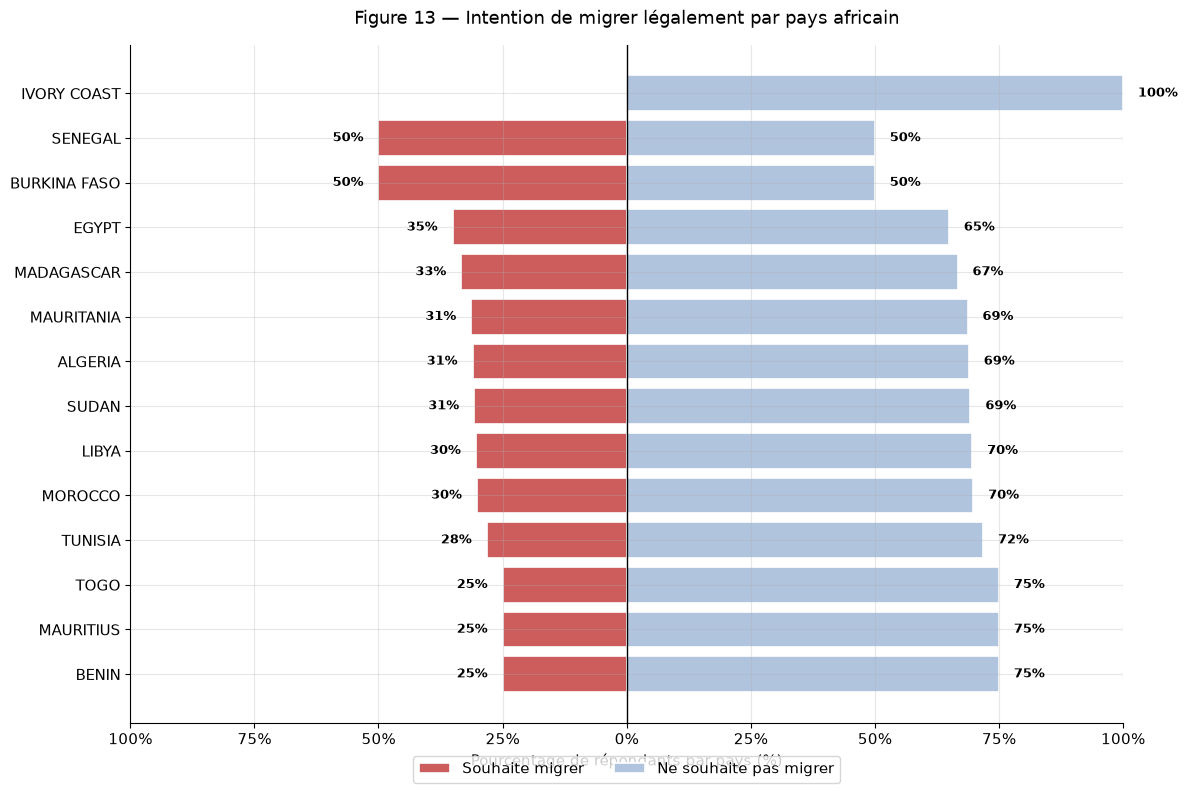

In [16]:
# Intention de migrer par pays africain — diagramme miroir
intention_par_pays = df_africa.groupby("Country")["intention_to_migrate_legal"].value_counts(normalize=True).unstack() * 100
intention_par_pays = intention_par_pays.reindex(columns=[0, 1], fill_value=0)
intention_par_pays.columns = ["Non", "Oui"]
intention_par_pays = intention_par_pays.sort_values("Oui", ascending=True)
pays = intention_par_pays.index
oui = intention_par_pays["Oui"].values
non = intention_par_pays["Non"].values
plt.figure(figsize=(12, 8))
plt.barh(pays, -oui, color="indianred", edgecolor="white", linewidth=1.2, label="Souhaite migrer")
plt.barh(pays, non, color="lightsteelblue", edgecolor="white", linewidth=1.2, label="Ne souhaite pas migrer")
for i, (o, n) in enumerate(zip(oui, non)):
    plt.text(-o - 3, i, f"{o:.0f}%", va="center", ha="right", fontsize=9, fontweight="bold")
    plt.text(n + 3, i, f"{n:.0f}%", va="center", ha="left", fontsize=9, fontweight="bold")
plt.axvline(0, color="black", linewidth=1)
plt.xlim(-100, 100)
plt.xticks([-100, -75, -50, -25, 0, 25, 50, 75, 100], ["100%", "75%", "50%", "25%", "0%", "25%", "50%", "75%", "100%"])
plt.xlabel("Pourcentage de répondants par pays (%)")
plt.title("Figure 13 — Intention de migrer légalement par pays africain", fontsize=13, pad=15)
plt.legend(loc="lower center", bbox_to_anchor=(0.5, -0.10), ncol=2, fontsize=11)
plt.tight_layout()
plt.show()

Diagramme divergent par pays. Le `reindex(columns=[0, 1], fill_value=0)` sécurise les groupes où une seule modalité est observée, situation fréquente pour les petits effectifs.

### Intention de migrer illégalement

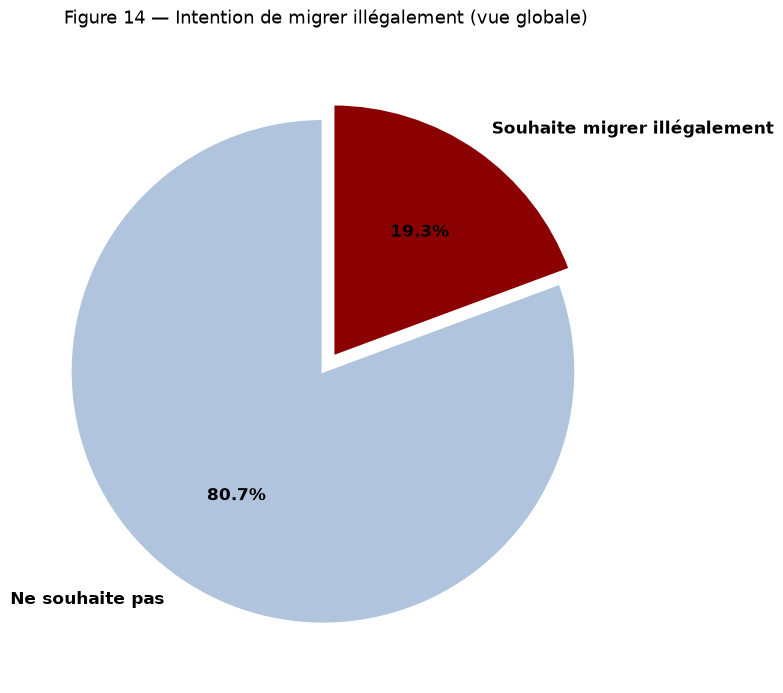

In [17]:
correspondance = {0: "Ne souhaite pas", 1: "Souhaite migrer illégalement"}
intention_il = df_africa["intention_to_migrate_illegal"].value_counts(normalize=True).sort_index() * 100
intention_il.index = intention_il.index.map(correspondance)
plt.figure(figsize=(8, 8))
plt.pie(intention_il.values, labels=intention_il.index, autopct="%1.1f%%", colors=["lightsteelblue", "darkred"], startangle=90, explode=[0.02, 0.05], wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 12, "fontweight": "bold"})
plt.title("Figure 14 — Intention de migrer illégalement (vue globale)", fontsize=13, pad=20)
plt.tight_layout()
plt.show()

Vue globale de `intention_to_migrate_illegal`. Cette variable est issue d'une question sensible : elle est exposée à un biais de désirabilité sociale, dont l'ampleur dépend du mode de collecte (anonymat, auto-administration). Ce biais est à garder en tête lors de la comparaison des deux sources.

### Bancarisation et envois de fonds

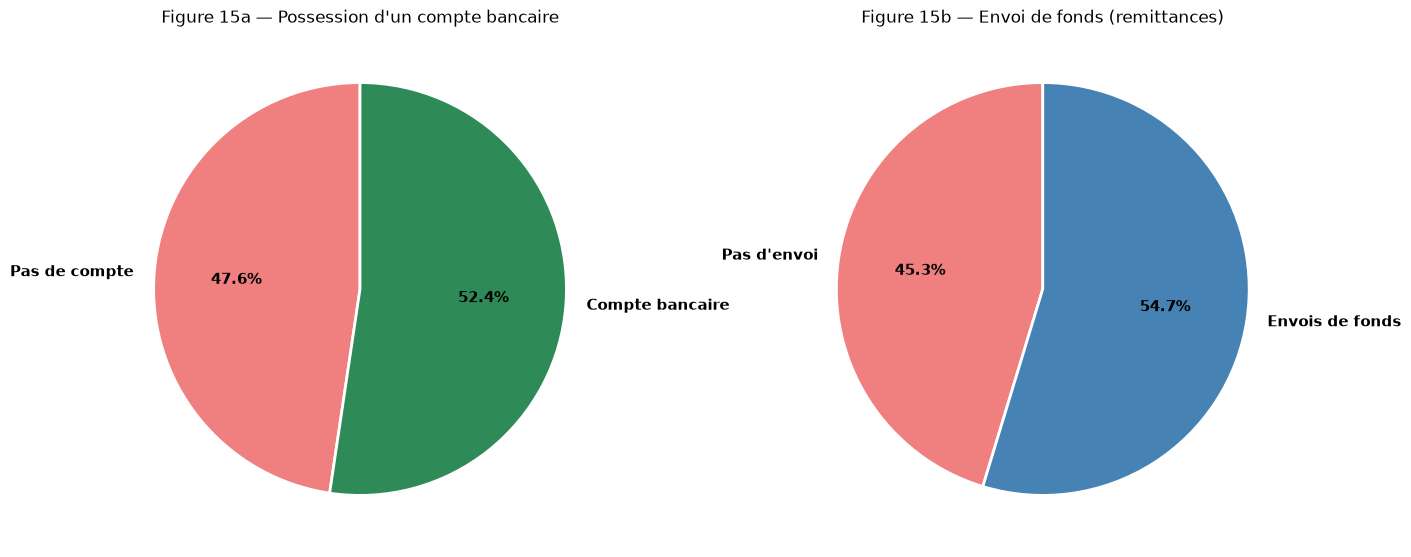

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

correspondance_b = {0: "Pas de compte", 1: "Compte bancaire"}
bank = df_africa["Bankaccount"].value_counts(normalize=True).sort_index() * 100
bank.index = bank.index.map(correspondance_b)
axes[0].pie(bank.values, labels=bank.index, autopct="%1.1f%%", colors=["lightcoral", "seagreen"], startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 11, "fontweight": "bold"})
axes[0].set_title("Figure 15a — Possession d'un compte bancaire", fontsize=12)

correspondance_r = {0: "Pas d'envoi", 1: "Envois de fonds"}
remit = df_africa["Remit"].value_counts(normalize=True).sort_index() * 100
remit.index = remit.index.map(correspondance_r)
axes[1].pie(remit.values, labels=remit.index, autopct="%1.1f%%", colors=["lightcoral", "steelblue"], startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 11, "fontweight": "bold"})
axes[1].set_title("Figure 15b — Envoi de fonds (remittances)", fontsize=12)

plt.tight_layout()
plt.show()

Deux variables binaires présentées côte à côte grâce à `plt.subplots(1, 2)` ; chaque sous-graphique est piloté via son objet `Axes` (`axes[0]`, `axes[1]`).

## Partie 3 — Variables issues du questionnaire (⚠️ imputées par Monte Carlo)

Ces variables n'ont été renseignées que par les répondants du questionnaire ; pour toutes les autres lignes, elles ont été tirées au hasard dans la distribution observée (N4). Les graphiques de cette partie décrivent donc essentiellement la distribution de l'échantillon source, propagée à toute la base.

### ⚠️ Variable imputée : taille du ménage

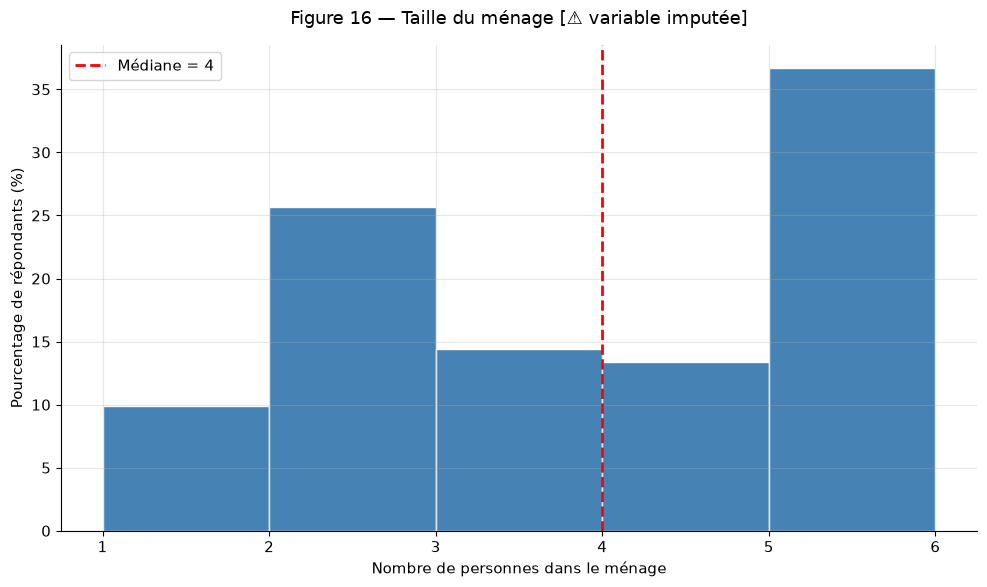

Taille moyenne : 3.4 personnes | Médiane : 4


In [19]:
plt.figure(figsize=(10, 6))
poids = np.ones_like(df_africa["Taille_menage"]) / len(df_africa) * 100
plt.hist(df_africa["Taille_menage"], bins=range(int(df_africa["Taille_menage"].min()), int(df_africa["Taille_menage"].max()) + 2), weights=poids, color="steelblue", edgecolor="white")
plt.axvline(df_africa["Taille_menage"].median(), color="red", linestyle="--", linewidth=2, label=f"Médiane = {df_africa['Taille_menage'].median():.0f}")
plt.xlabel("Nombre de personnes dans le ménage")
plt.ylabel("Pourcentage de répondants (%)")
plt.title("Figure 16 — Taille du ménage [⚠️ variable imputée]", fontsize=13, pad=15)
plt.legend()
plt.tight_layout()
plt.show()
print(f"Taille moyenne : {df_africa['Taille_menage'].mean():.1f} personnes | Médiane : {df_africa['Taille_menage'].median():.0f}")

Histogramme à classes unitaires (`bins=range(min, max + 2)`), adapté à une variable discrète, avec la médiane en surimpression.

### ⚠️ Variable imputée : revenu du ménage

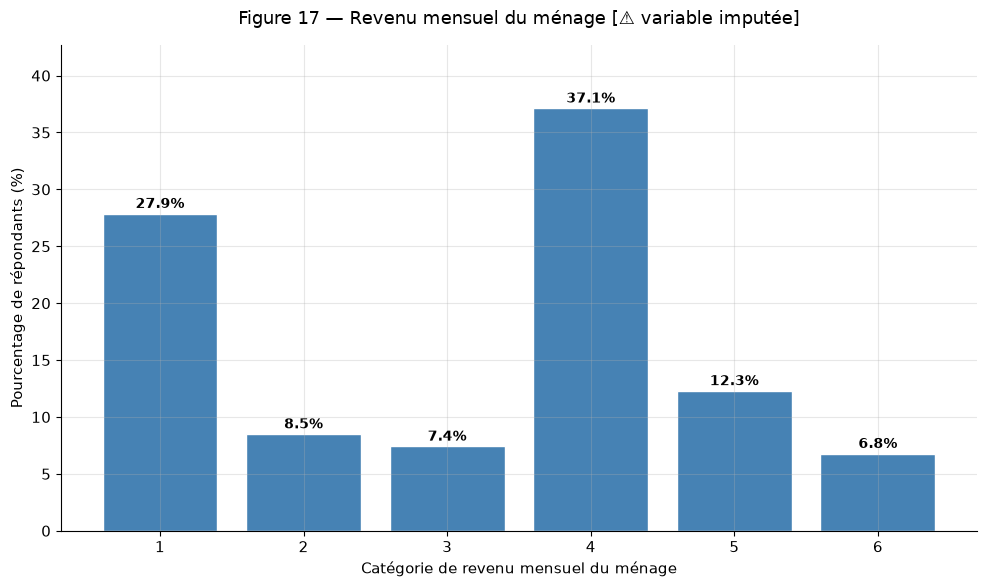

In [20]:
revenu = df_africa["Revenu"].value_counts(normalize=True).sort_index() * 100
plt.figure(figsize=(10, 6))
bars = plt.bar(revenu.index, revenu.values, color="steelblue", edgecolor="white")
for bar, valeur in zip(bars, revenu.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f"{valeur:.1f}%", ha="center", fontsize=10, fontweight="bold")
plt.xlabel("Catégorie de revenu mensuel du ménage")
plt.ylabel("Pourcentage de répondants (%)")
plt.title("Figure 17 — Revenu mensuel du ménage [⚠️ variable imputée]", fontsize=13, pad=15)
plt.ylim(0, max(revenu.values) * 1.15)
plt.tight_layout()
plt.show()

Barres verticales par tranche de revenu, ordre des codes conservé. Codage : 1 à 5 = tranches croissantes de revenu mensuel, 6 = refus de répondre. La modalité 6 n'étant pas une tranche, elle devrait être recodée en manquant avant toute analyse ordinale.

### ⚠️ Variables imputées : sources de revenu

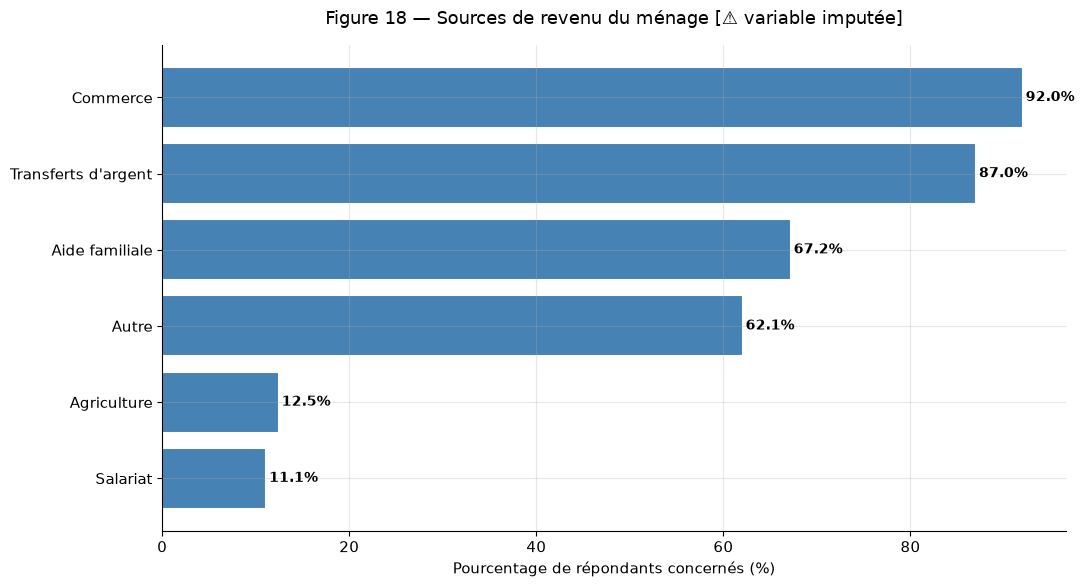

In [21]:
sources = {
    "Salariat": df_africa["Source_revenu_salariat"].mean() * 100,
    "Commerce": df_africa["Source_revenu_commerce"].mean() * 100,
    "Agriculture": df_africa["Source_revenu_agriculture"].mean() * 100,
    "Aide familiale": df_africa["Source_revenu_aide_familiale"].mean() * 100,
    "Transferts d'argent": df_africa["Source_revenu_transferts"].mean() * 100,
    "Autre": df_africa["Source_revenu_autre"].mean() * 100
}
sources_triees = dict(sorted(sources.items(), key=lambda x: x[1]))
plt.figure(figsize=(11, 6))
bars = plt.barh(list(sources_triees.keys()), list(sources_triees.values()), color="steelblue", edgecolor="white", linewidth=1.5)
for bar, valeur in zip(bars, sources_triees.values()):
    plt.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2, f"{valeur:.1f}%", va="center", fontsize=10, fontweight="bold")
plt.xlabel("Pourcentage de répondants concernés (%)")
plt.title("Figure 18 — Sources de revenu du ménage [⚠️ variable imputée]", fontsize=13, pad=15)
plt.tight_layout()
plt.show()

Six indicatrices 0/1 issues d'une question à choix multiples : la moyenne de chaque colonne donne la part de répondants concernés. Plusieurs réponses étant possibles, les pourcentages ne somment pas à 100 %.

### ⚠️ Variable imputée : choc économique

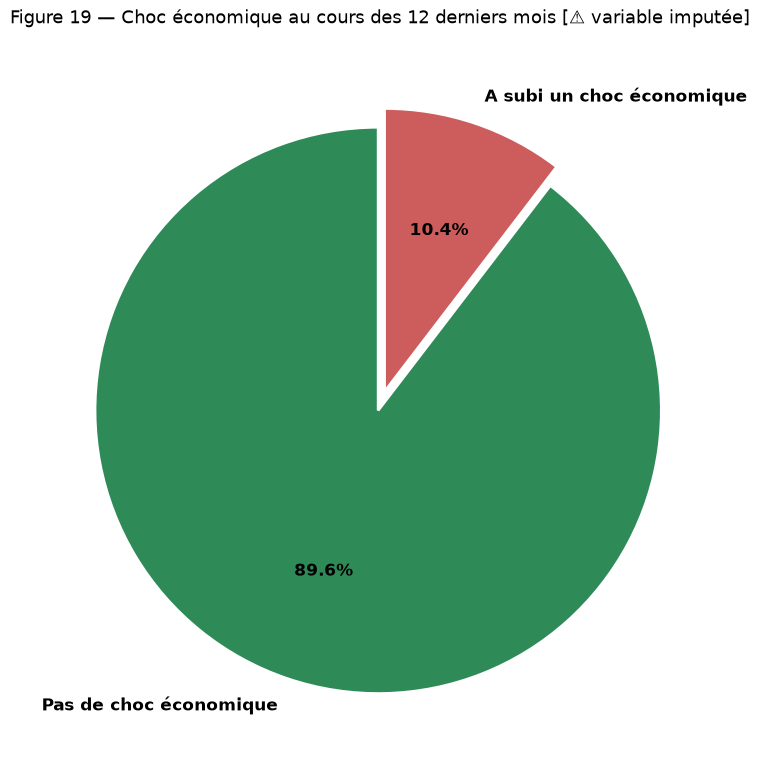

In [22]:
correspondance = {0: "Pas de choc économique", 1: "A subi un choc économique"}
choc = df_africa["Choc_economique"].value_counts(normalize=True).sort_index() * 100
choc.index = choc.index.map(correspondance)
plt.figure(figsize=(8, 8))
plt.pie(choc.values, labels=choc.index, autopct="%1.1f%%", colors=["seagreen", "indianred"], startangle=90, explode=[0.02, 0.05], wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 12, "fontweight": "bold"})
plt.title("Figure 19 — Choc économique au cours des 12 derniers mois [⚠️ variable imputée]", fontsize=13, pad=20)
plt.tight_layout()
plt.show()

Diagramme en secteurs d'une variable binaire imputée.

### ⚠️ Variable imputée : accès au crédit

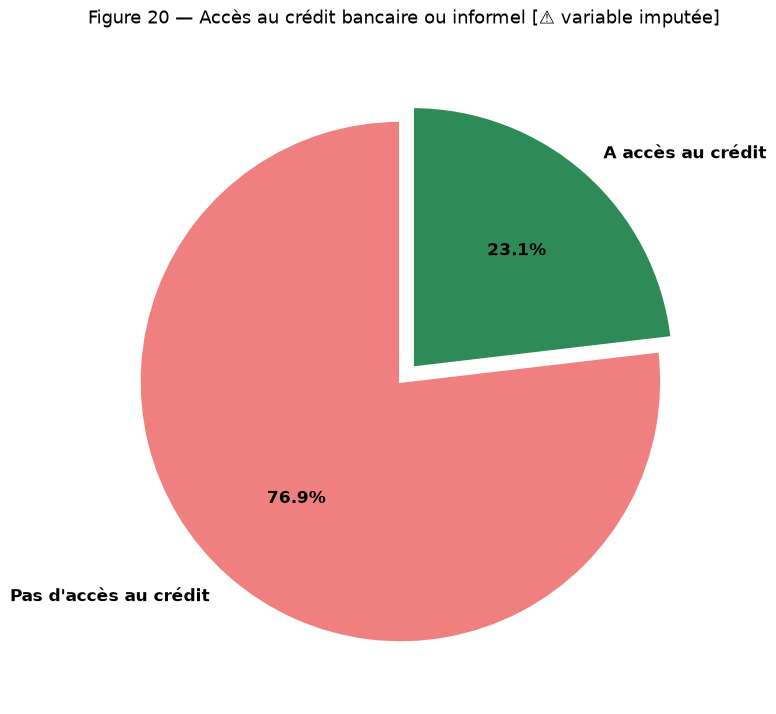

In [23]:
correspondance = {0: "Pas d'accès au crédit", 1: "A accès au crédit"}
credit = df_africa["Acces_credit"].value_counts(normalize=True).sort_index() * 100
credit.index = credit.index.map(correspondance)
plt.figure(figsize=(8, 8))
plt.pie(credit.values, labels=credit.index, autopct="%1.1f%%", colors=["lightcoral", "seagreen"], startangle=90, explode=[0.02, 0.05], wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 12, "fontweight": "bold"})
plt.title("Figure 20 — Accès au crédit bancaire ou informel [⚠️ variable imputée]", fontsize=13, pad=20)
plt.tight_layout()
plt.show()

Diagramme en secteurs d'une variable binaire imputée.

### ⚠️ Variable imputée : proches en Europe

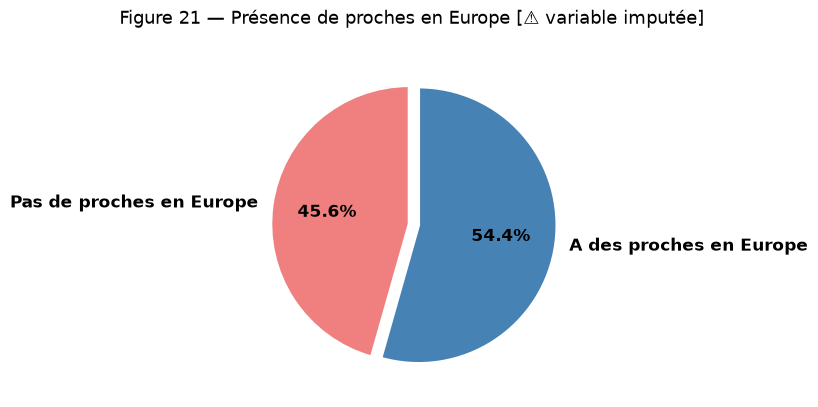

In [24]:
correspondance = {0: "Pas de proches en Europe", 1: "A des proches en Europe"}
proches = df_africa["Proches_europe"].value_counts(normalize=True).sort_index() * 100
proches.index = proches.index.map(correspondance)

plt.figure(figsize=(8, 8))
plt.pie(proches.values, labels=proches.index, autopct="%1.1f%%", colors=["lightcoral", "steelblue"], startangle=90, explode=[0.02, 0.05], wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 12, "fontweight": "bold"})
plt.title("Figure 21 — Présence de proches en Europe [⚠️ variable imputée]", fontsize=13, pad=20)
plt.tight_layout()
plt.show()

Diagramme en secteurs d'une variable binaire imputée.

### ⚠️ Variables imputées : souhait de naturalisation et de retour

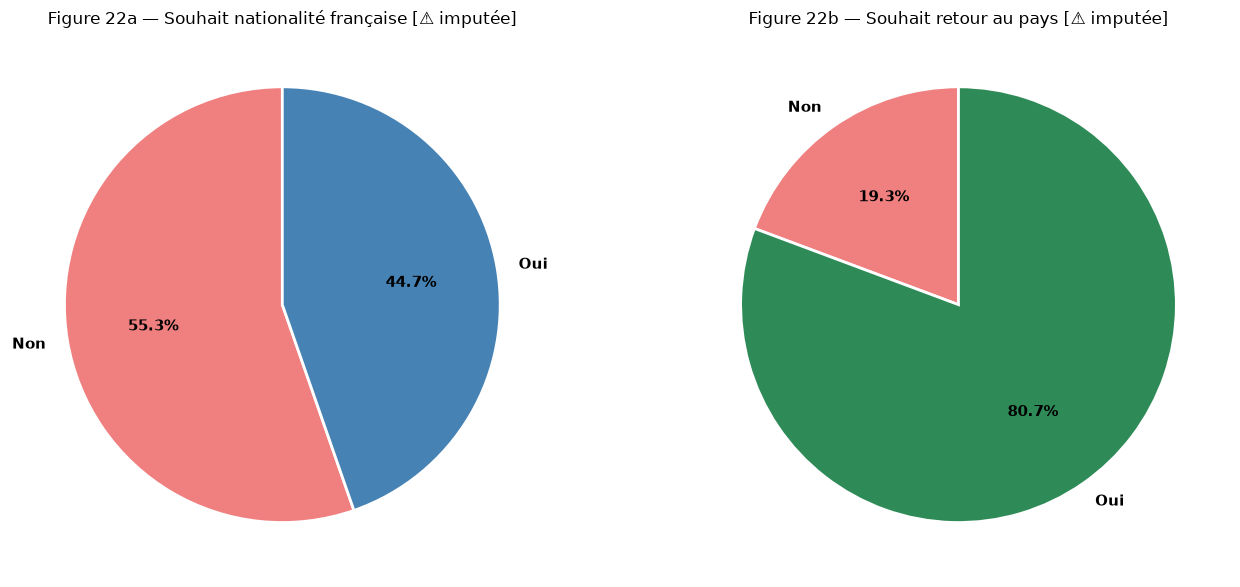

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

correspondance_n = {0: "Non", 1: "Oui"}
nat = df_africa["Nationalite_francaise"].value_counts(normalize=True).sort_index() * 100
nat.index = nat.index.map(correspondance_n)
axes[0].pie(nat.values, labels=nat.index, autopct="%1.1f%%", colors=["lightcoral", "steelblue"], startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 11, "fontweight": "bold"})
axes[0].set_title("Figure 22a — Souhait nationalité française [⚠️ imputée]", fontsize=12)

correspondance_r = {0: "Non", 1: "Oui"}
retour = df_africa["Retour_pays"].value_counts(normalize=True).sort_index() * 100
retour.index = retour.index.map(correspondance_r)
axes[1].pie(retour.values, labels=retour.index, autopct="%1.1f%%", colors=["lightcoral", "seagreen"], startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 11, "fontweight": "bold"})
axes[1].set_title("Figure 22b — Souhait retour au pays [⚠️ imputée]", fontsize=12)

plt.tight_layout()
plt.show()

Deux variables binaires côte à côte (`plt.subplots(1, 2)`).

## Partie 4 — Croisements avec la variable cible

Chaque bloc croise `intention_to_migrate_legal` avec une variable explicative. Méthode commune :

- `pd.crosstab(x, y, normalize="index") * 100` : distribution de la cible **au sein de chaque modalité** de la variable explicative, ce qui neutralise les différences d'effectifs entre modalités ;
- barres empilées à 100 % (`plot(kind="bar", stacked=True)`), la part de `1` étant annotée au centre de son segment ;
- les croisements sont séparés en deux blocs selon que la variable explicative a été imputée par Monte Carlo ou non.

### Croisements avec des variables non imputées par Monte Carlo

#### Croisement : intention × âge

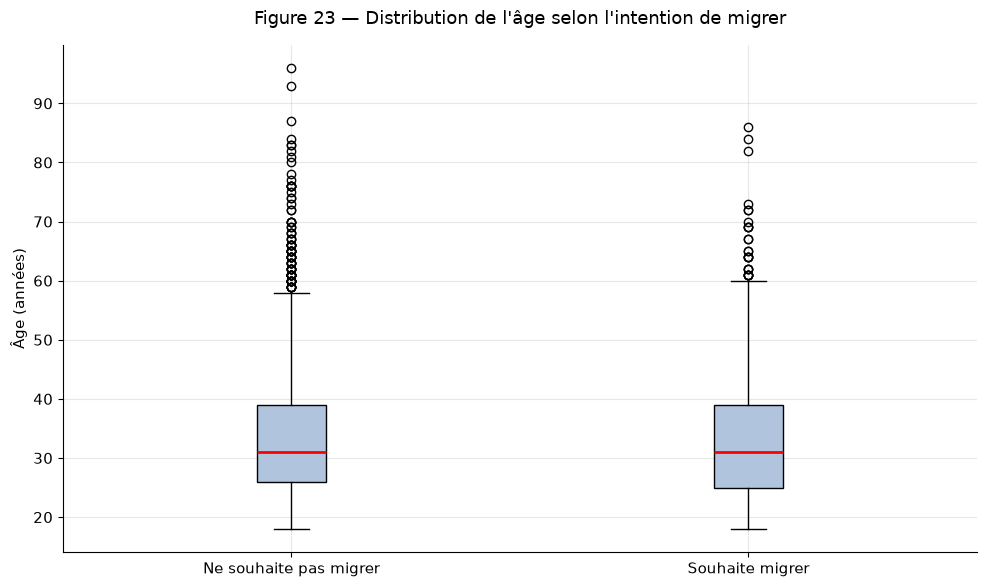

Âge moyen — Ne souhaite pas migrer : 33.5 ans
Âge moyen — Souhaite migrer : 33.2 ans


In [26]:
plt.figure(figsize=(10, 6))
df_non = df_africa[df_africa["intention_to_migrate_legal"] == 0]["Age"]
df_oui = df_africa[df_africa["intention_to_migrate_legal"] == 1]["Age"]
plt.boxplot([df_non, df_oui], tick_labels=["Ne souhaite pas migrer", "Souhaite migrer"], patch_artist=True, boxprops=dict(facecolor="lightsteelblue"), medianprops=dict(color="red", linewidth=2))
plt.ylabel("Âge (années)")
plt.title("Figure 23 — Distribution de l'âge selon l'intention de migrer", fontsize=13, pad=15)
plt.tight_layout()
plt.show()
print(f"Âge moyen — Ne souhaite pas migrer : {df_non.mean():.1f} ans")
print(f"Âge moyen — Souhaite migrer : {df_oui.mean():.1f} ans")

Variable explicative continue : les distributions d'âge des deux groupes de la cible sont comparées par boîtes à moustaches (`plt.boxplot`), complétées par la moyenne de chaque groupe. La boîte représente l'intervalle interquartile, la ligne rouge la médiane.

#### Croisement : intention × niveau d'éducation

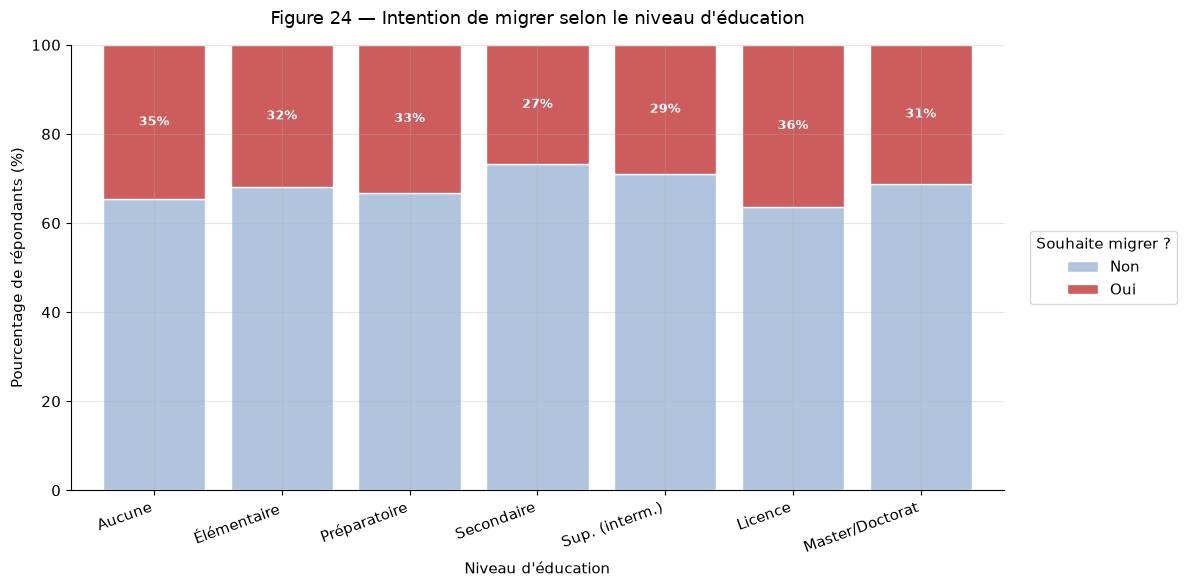

In [27]:
correspondance = {1: "Aucune", 2: "Élémentaire", 3: "Préparatoire", 4: "Secondaire", 5: "Sup. (interm.)", 6: "Licence", 7: "Master/Doctorat"}
crosstab = pd.crosstab(df_africa["Educationf"], df_africa["intention_to_migrate_legal"], normalize="index") * 100
crosstab.index = crosstab.index.map(correspondance)
crosstab.columns = ["Non", "Oui"]

fig, ax = plt.subplots(figsize=(12, 6))
crosstab.plot(kind="bar", stacked=True, ax=ax, color=["lightsteelblue", "indianred"], edgecolor="white", width=0.8)
ax.set_xlabel("Niveau d'éducation")
ax.set_ylabel("Pourcentage de répondants (%)")
ax.set_title("Figure 24 — Intention de migrer selon le niveau d'éducation", fontsize=13, pad=15)
ax.legend(title="Souhaite migrer ?", loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_xticklabels(crosstab.index, rotation=20, ha="right")
ax.set_ylim(0, 100)
for i, education in enumerate(crosstab.index):
    pct_oui = crosstab.loc[education, "Oui"]
    ax.text(i, crosstab.loc[education, "Non"] + pct_oui/2, f"{pct_oui:.0f}%", ha="center", va="center", fontsize=9, fontweight="bold", color="white")
plt.tight_layout()
plt.show()

Tableau de contingence normalisé par ligne et barres empilées verticales ; l'ordre des niveaux d'éducation est conservé pour faire apparaître une éventuelle tendance monotone.

#### Croisement : intention × situation professionnelle

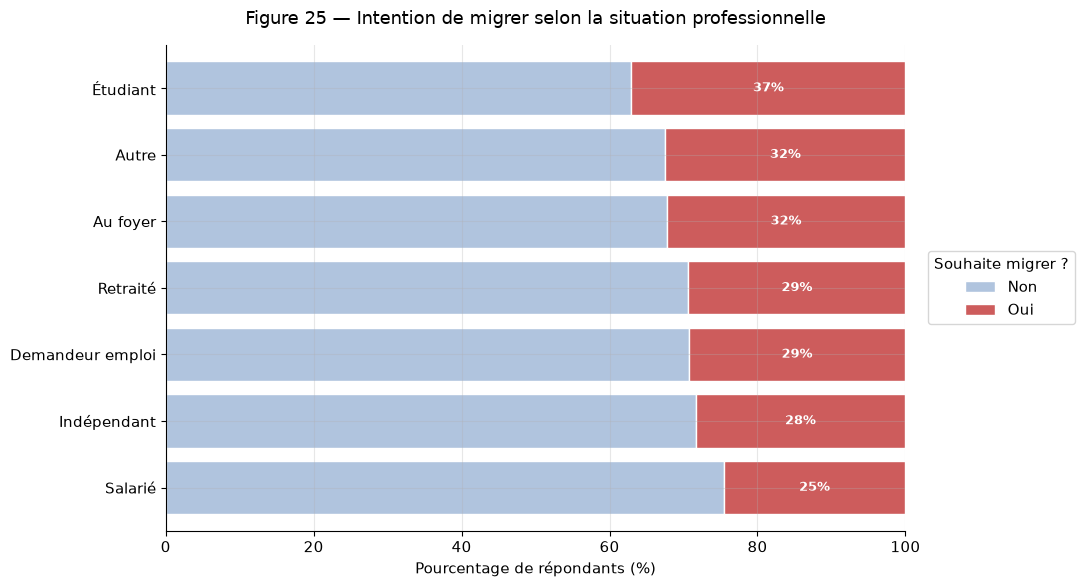

In [28]:
correspondance = {1: "Salarié", 2: "Indépendant", 3: "Retraité", 4: "Au foyer", 5: "Étudiant", 6: "Demandeur emploi", 7: "Autre"}
crosstab = pd.crosstab(df_africa["Professional situationf"], df_africa["intention_to_migrate_legal"], normalize="index") * 100
crosstab.index = crosstab.index.map(correspondance)
crosstab.columns = ["Non", "Oui"]
crosstab = crosstab.sort_values("Oui", ascending=True)

fig, ax = plt.subplots(figsize=(11, 6))
crosstab.plot(kind="barh", stacked=True, ax=ax, color=["lightsteelblue", "indianred"], edgecolor="white", width=0.8)
ax.set_xlabel("Pourcentage de répondants (%)")
ax.set_ylabel("")
ax.set_title("Figure 25 — Intention de migrer selon la situation professionnelle", fontsize=13, pad=15)
ax.legend(title="Souhaite migrer ?", loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_xlim(0, 100)
for i, situation in enumerate(crosstab.index):
    pct_oui = crosstab.loc[situation, "Oui"]
    ax.text(crosstab.loc[situation, "Non"] + pct_oui/2, i, f"{pct_oui:.0f}%", ha="center", va="center", fontsize=9, fontweight="bold", color="white")
plt.tight_layout()
plt.show()

Même méthode en barres horizontales, triées par part de `1` croissante (`sort_values("Oui")`).

#### Croisement : intention × genre

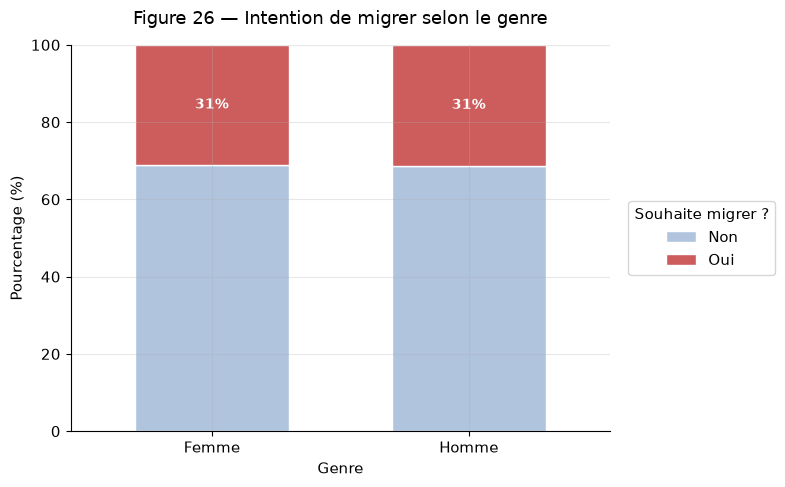

In [29]:
correspondance = {0: "Femme", 1: "Homme"}
crosstab = pd.crosstab(df_africa["Genderf"], df_africa["intention_to_migrate_legal"], normalize="index") * 100
crosstab.index = crosstab.index.map(correspondance)
crosstab.columns = ["Non", "Oui"]

fig, ax = plt.subplots(figsize=(8, 5))
crosstab.plot(kind="bar", stacked=True, ax=ax, color=["lightsteelblue", "indianred"], edgecolor="white", width=0.6)
ax.set_xlabel("Genre")
ax.set_ylabel("Pourcentage (%)")
ax.set_title("Figure 26 — Intention de migrer selon le genre", fontsize=13, pad=15)
ax.legend(title="Souhaite migrer ?", loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_xticklabels(crosstab.index, rotation=0)
ax.set_ylim(0, 100)
for i, genre in enumerate(crosstab.index):
    pct_oui = crosstab.loc[genre, "Oui"]
    ax.text(i, crosstab.loc[genre, "Non"] + pct_oui/2, f"{pct_oui:.0f}%", ha="center", va="center", fontsize=10, fontweight="bold", color="white")
plt.tight_layout()
plt.show()

Tableau de contingence normalisé par ligne sur une variable binaire.

#### Croisement : intention × corruption perçue

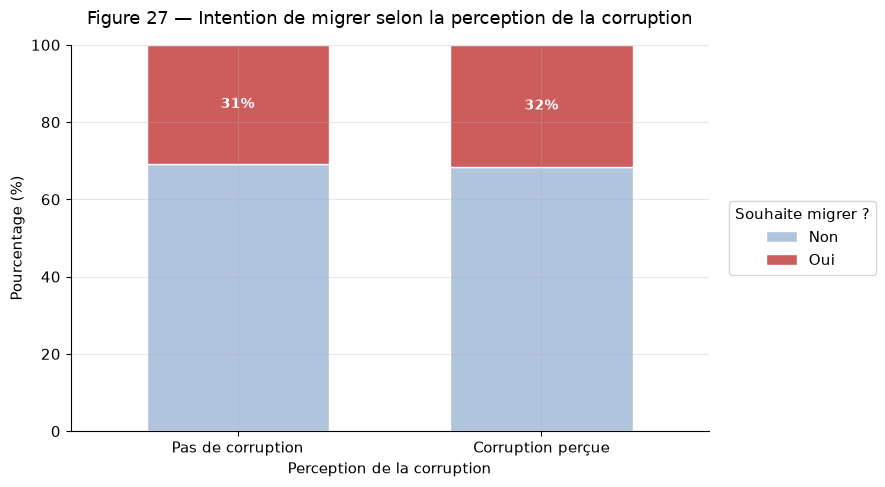

In [30]:
correspondance = {0: "Pas de corruption", 1: "Corruption perçue"}
crosstab = pd.crosstab(df_africa["Corruption (0  1)"], df_africa["intention_to_migrate_legal"], normalize="index") * 100
crosstab.index = crosstab.index.map(correspondance)
crosstab.columns = ["Non", "Oui"]

fig, ax = plt.subplots(figsize=(9, 5))
crosstab.plot(kind="bar", stacked=True, ax=ax, color=["lightsteelblue", "indianred"], edgecolor="white", width=0.6)
ax.set_xlabel("Perception de la corruption")
ax.set_ylabel("Pourcentage (%)")
ax.set_title("Figure 27 — Intention de migrer selon la perception de la corruption", fontsize=13, pad=15)
ax.legend(title="Souhaite migrer ?", loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_xticklabels(crosstab.index, rotation=0)
ax.set_ylim(0, 100)
for i, perception in enumerate(crosstab.index):
    pct_oui = crosstab.loc[perception, "Oui"]
    ax.text(i, crosstab.loc[perception, "Non"] + pct_oui/2, f"{pct_oui:.0f}%", ha="center", va="center", fontsize=10, fontweight="bold", color="white")
plt.tight_layout()
plt.show()

Tableau de contingence normalisé par ligne sur une variable binaire.

#### Croisement : intention × confiance institutionnelle

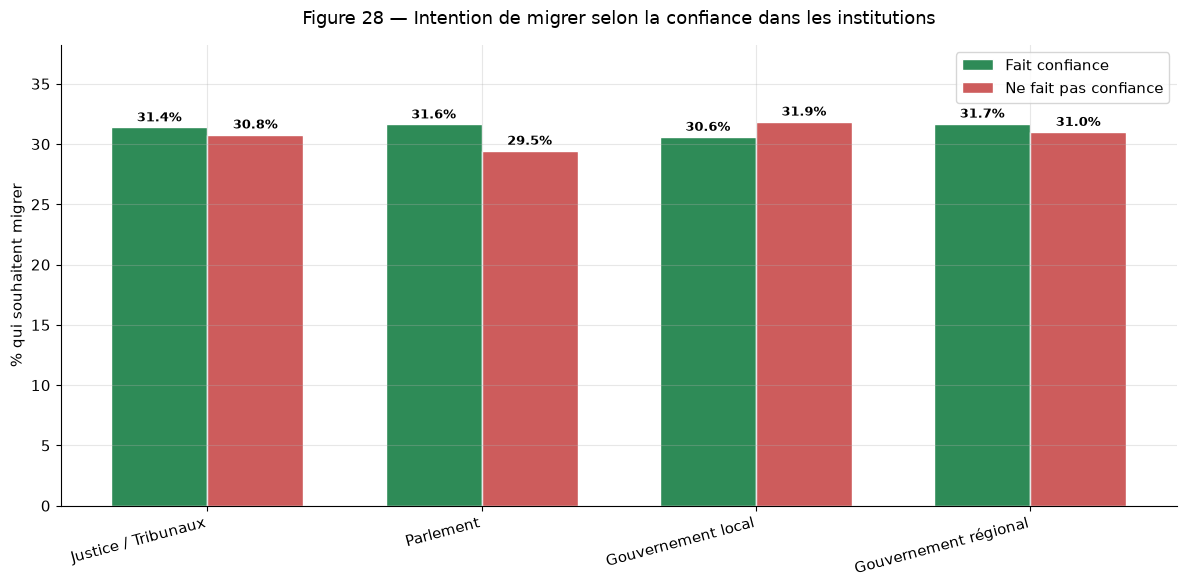

In [31]:
institutions_cols = {
    "Justice / Tribunaux": "TrustCourts",
    "Parlement": "Trust_Parliament",
    "Gouvernement local": "TrustLocalGovernement",
    "Gouvernement régional": "Trust_Regiol_Governement"
}

resultats = {}
for nom, col in institutions_cols.items():
    pct_migrer_si_confiance = df_africa[df_africa[col] == 1]["intention_to_migrate_legal"].mean() * 100
    pct_migrer_si_pas_confiance = df_africa[df_africa[col] == 0]["intention_to_migrate_legal"].mean() * 100
    resultats[nom] = (pct_migrer_si_confiance, pct_migrer_si_pas_confiance)

institutions_noms = list(resultats.keys())
avec_confiance = [resultats[i][0] for i in institutions_noms]
sans_confiance = [resultats[i][1] for i in institutions_noms]
x = np.arange(len(institutions_noms))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - width/2, avec_confiance, width, label="Fait confiance", color="seagreen", edgecolor="white")
bars2 = ax.bar(x + width/2, sans_confiance, width, label="Ne fait pas confiance", color="indianred", edgecolor="white")

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f"{bar.get_height():.1f}%", ha="center", fontsize=9, fontweight="bold")

ax.set_ylabel("% qui souhaitent migrer")
ax.set_title("Figure 28 — Intention de migrer selon la confiance dans les institutions", fontsize=13, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(institutions_noms, rotation=15, ha="right")
ax.legend()
ax.set_ylim(0, max(max(avec_confiance), max(sans_confiance)) * 1.2)
plt.tight_layout()
plt.show()

Pour chaque institution, la part de `1` de la cible est calculée séparément dans le groupe « confiance » et dans le groupe « défiance » (filtrage booléen puis `mean()`). Les deux taux sont comparés en barres groupées, positionnées de part et d'autre de `np.arange(n)` avec un décalage de `width / 2`.

#### Croisement : intention × compte bancaire

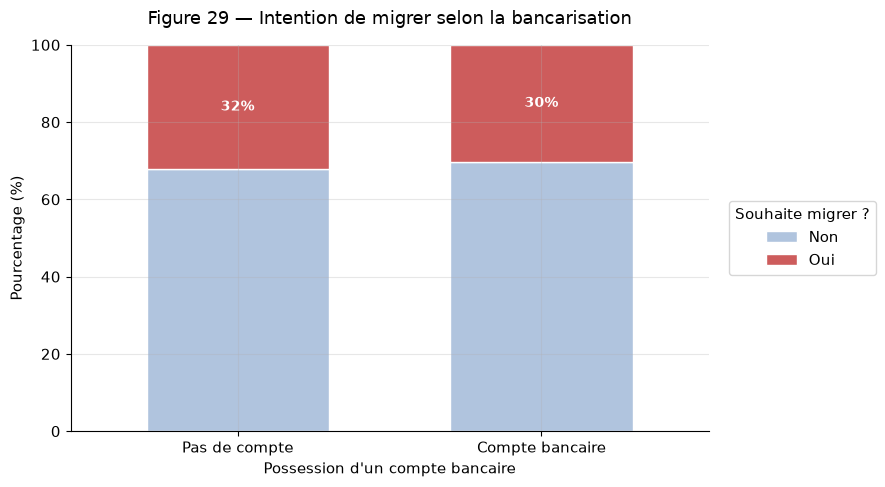

In [32]:
correspondance = {0: "Pas de compte", 1: "Compte bancaire"}
crosstab = pd.crosstab(df_africa["Bankaccount"], df_africa["intention_to_migrate_legal"], normalize="index") * 100
crosstab.index = crosstab.index.map(correspondance)
crosstab.columns = ["Non", "Oui"]

fig, ax = plt.subplots(figsize=(9, 5))
crosstab.plot(kind="bar", stacked=True, ax=ax, color=["lightsteelblue", "indianred"], edgecolor="white", width=0.6)
ax.set_xlabel("Possession d'un compte bancaire")
ax.set_ylabel("Pourcentage (%)")
ax.set_title("Figure 29 — Intention de migrer selon la bancarisation", fontsize=13, pad=15)
ax.legend(title="Souhaite migrer ?", loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_xticklabels(crosstab.index, rotation=0)
ax.set_ylim(0, 100)
for i, situation in enumerate(crosstab.index):
    pct_oui = crosstab.loc[situation, "Oui"]
    ax.text(i, crosstab.loc[situation, "Non"] + pct_oui/2, f"{pct_oui:.0f}%", ha="center", va="center", fontsize=10, fontweight="bold", color="white")
plt.tight_layout()
plt.show()

Tableau de contingence normalisé par ligne sur une variable binaire.

### ⚠️ Croisements avec des variables imputées par Monte Carlo

Une variable imputée par tirage indépendant n'a, par construction, aucune corrélation avec la cible sur les lignes imputées. Les croisements ci-dessous sont conservés pour illustrer cet effet de la méthode d'imputation ; ils ne permettent pas de conclure sur la relation entre les variables.

#### ⚠️ Croisement : intention × revenu (variable imputée)

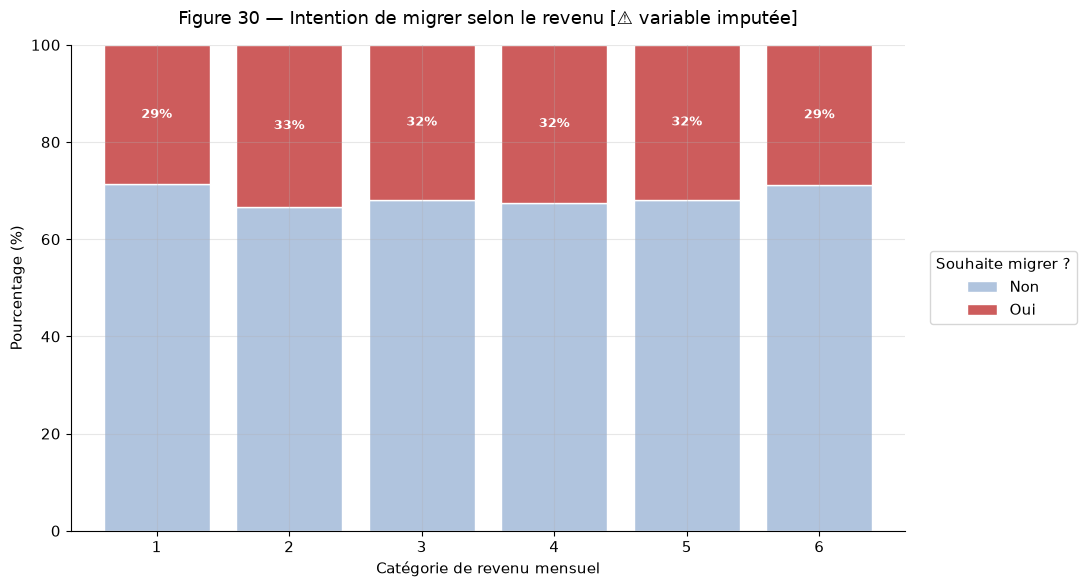

In [33]:
crosstab = pd.crosstab(df_africa["Revenu"], df_africa["intention_to_migrate_legal"], normalize="index") * 100
crosstab.columns = ["Non", "Oui"]

fig, ax = plt.subplots(figsize=(11, 6))
crosstab.plot(kind="bar", stacked=True, ax=ax, color=["lightsteelblue", "indianred"], edgecolor="white", width=0.8)
ax.set_xlabel("Catégorie de revenu mensuel")
ax.set_ylabel("Pourcentage (%)")
ax.set_title("Figure 30 — Intention de migrer selon le revenu [⚠️ variable imputée]", fontsize=13, pad=15)
ax.legend(title="Souhaite migrer ?", loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_xticklabels(crosstab.index, rotation=0)
ax.set_ylim(0, 100)
for i, niveau in enumerate(crosstab.index):
    pct_oui = crosstab.loc[niveau, "Oui"]
    ax.text(i, crosstab.loc[niveau, "Non"] + pct_oui/2, f"{pct_oui:.0f}%", ha="center", va="center", fontsize=9, fontweight="bold", color="white")
plt.tight_layout()
plt.show()

Tableau de contingence normalisé par ligne. Un profil plat (même part de `1` dans toutes les modalités) est l'effet attendu de l'imputation indépendante. La modalité 6 (refus de répondre) devrait être exclue.

#### ⚠️ Croisement : intention × choc économique (variable imputée)

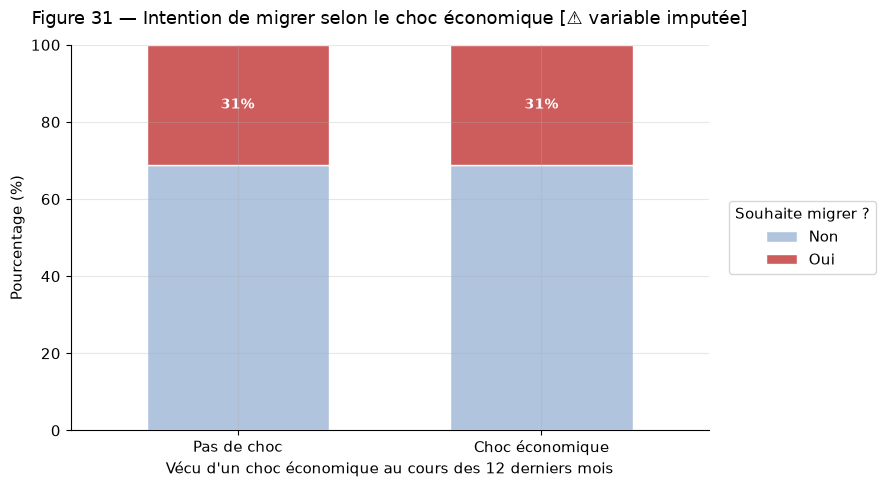

In [34]:
correspondance = {0: "Pas de choc", 1: "Choc économique"}
crosstab = pd.crosstab(df_africa["Choc_economique"], df_africa["intention_to_migrate_legal"], normalize="index") * 100
crosstab.index = crosstab.index.map(correspondance)
crosstab.columns = ["Non", "Oui"]

fig, ax = plt.subplots(figsize=(9, 5))
crosstab.plot(kind="bar", stacked=True, ax=ax, color=["lightsteelblue", "indianred"], edgecolor="white", width=0.6)
ax.set_xlabel("Vécu d'un choc économique au cours des 12 derniers mois")
ax.set_ylabel("Pourcentage (%)")
ax.set_title("Figure 31 — Intention de migrer selon le choc économique [⚠️ variable imputée]", fontsize=13, pad=15)
ax.legend(title="Souhaite migrer ?", loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_xticklabels(crosstab.index, rotation=0)
ax.set_ylim(0, 100)
for i, perception in enumerate(crosstab.index):
    pct_oui = crosstab.loc[perception, "Oui"]
    ax.text(i, crosstab.loc[perception, "Non"] + pct_oui/2, f"{pct_oui:.0f}%", ha="center", va="center", fontsize=10, fontweight="bold", color="white")
plt.tight_layout()
plt.show()

Même méthode ; même réserve d'interprétation.

#### ⚠️ Croisement : intention × accès au crédit (variable imputée)

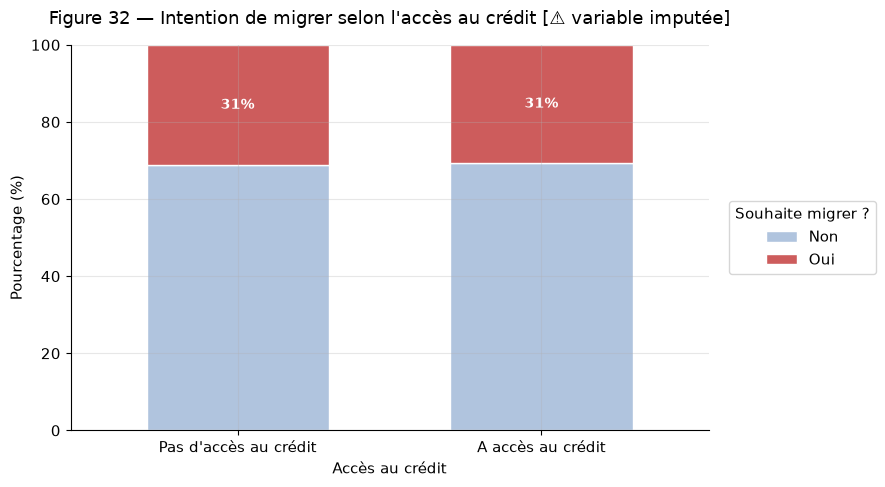

In [35]:
correspondance = {0: "Pas d'accès au crédit", 1: "A accès au crédit"}
crosstab = pd.crosstab(df_africa["Acces_credit"], df_africa["intention_to_migrate_legal"], normalize="index") * 100
crosstab.index = crosstab.index.map(correspondance)
crosstab.columns = ["Non", "Oui"]

fig, ax = plt.subplots(figsize=(9, 5))
crosstab.plot(kind="bar", stacked=True, ax=ax, color=["lightsteelblue", "indianred"], edgecolor="white", width=0.6)
ax.set_xlabel("Accès au crédit")
ax.set_ylabel("Pourcentage (%)")
ax.set_title("Figure 32 — Intention de migrer selon l'accès au crédit [⚠️ variable imputée]", fontsize=13, pad=15)
ax.legend(title="Souhaite migrer ?", loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_xticklabels(crosstab.index, rotation=0)
ax.set_ylim(0, 100)
for i, situation in enumerate(crosstab.index):
    pct_oui = crosstab.loc[situation, "Oui"]
    ax.text(i, crosstab.loc[situation, "Non"] + pct_oui/2, f"{pct_oui:.0f}%", ha="center", va="center", fontsize=10, fontweight="bold", color="white")
plt.tight_layout()
plt.show()

Même méthode ; même réserve d'interprétation.

#### ⚠️ Croisement : intention × proches en Europe (variable imputée)

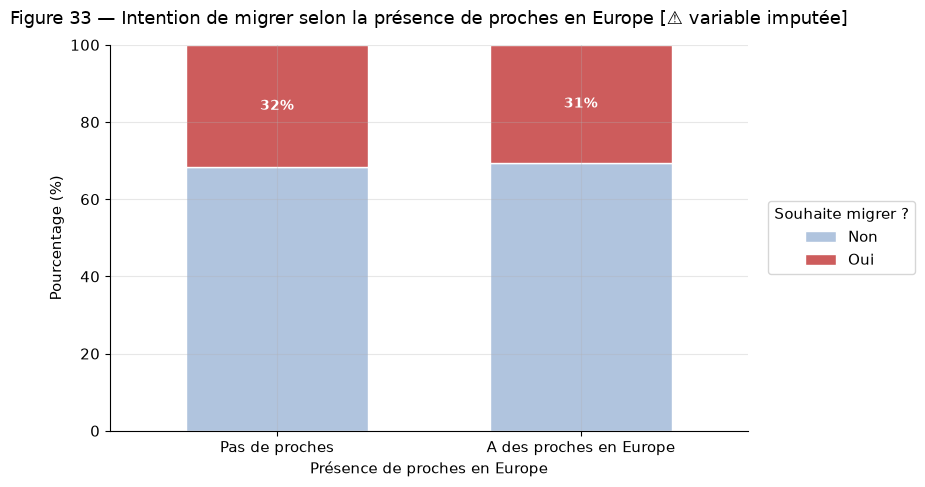

In [36]:
correspondance = {0: "Pas de proches", 1: "A des proches en Europe"}
crosstab = pd.crosstab(df_africa["Proches_europe"], df_africa["intention_to_migrate_legal"], normalize="index") * 100
crosstab.index = crosstab.index.map(correspondance)
crosstab.columns = ["Non", "Oui"]

fig, ax = plt.subplots(figsize=(9, 5))
crosstab.plot(kind="bar", stacked=True, ax=ax, color=["lightsteelblue", "indianred"], edgecolor="white", width=0.6)
ax.set_xlabel("Présence de proches en Europe")
ax.set_ylabel("Pourcentage (%)")
ax.set_title("Figure 33 — Intention de migrer selon la présence de proches en Europe [⚠️ variable imputée]", fontsize=13, pad=15)
ax.legend(title="Souhaite migrer ?", loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_xticklabels(crosstab.index, rotation=0)
ax.set_ylim(0, 100)
for i, perception in enumerate(crosstab.index):
    pct_oui = crosstab.loc[perception, "Oui"]
    ax.text(i, crosstab.loc[perception, "Non"] + pct_oui/2, f"{pct_oui:.0f}%", ha="center", va="center", fontsize=10, fontweight="bold", color="white")
plt.tight_layout()
plt.show()

Même méthode ; même réserve d'interprétation.

## Synthèse technique

Ce notebook enchaîne filtrage géographique, distributions univariées, puis croisements bivariés normalisés avec la variable cible. La traçabilité de l'origine de chaque variable (observée ou imputée) conditionne la lecture des croisements.

### Limites méthodologiques

- **Imputation Monte Carlo non conditionnelle** : elle préserve les distributions marginales mais annule les corrélations ; les croisements impliquant une variable imputée ne sont pas interprétables. Une imputation conditionnelle (hot-deck stratifié, MICE) ou une analyse restreinte aux lignes observées serait nécessaire.
- **Représentativité de l'échantillon source** : les variables imputées reproduisent la distribution du petit échantillon du questionnaire, avec toutes ses spécificités.
- **Petits effectifs** : pour les groupes de quelques répondants, les proportions sont saturées (0 % ou 100 %) ; il faudrait afficher l'effectif de chaque groupe ou fixer un effectif minimal d'affichage.
- **Analyse descriptive** : les écarts observés dans les croisements ne sont ni testés statistiquement (test du χ², intervalles de confiance) ni contrôlés pour les effets de structure entre variables explicatives (modèle multivarié, par exemple une régression logistique).